# SARGen: an automated, explainable SAR ADC generator in SKY130

**IEEE SSCS Code-a-Chip - ISSCC 2027**

| Name | Affiliation | Contact | IEEE member | SSCS member |
|---|---|---|---|---|
| Rajinthan Rameshkumar | Final-year undergraduate, Dept. of Electronic and Telecommunication Engineering, University of Moratuwa, Sri Lanka | rajinthan519@gmail.com, [rajinthan.com](https://rajinthan.com) | Yes | Yes |

## Abstract
Successive-approximation (SAR) ADCs are the workhorse of low-power data conversion, yet the path from a
specification ("I need N bits at f<sub>s</sub>") to sized transistors is usually hidden in a designer's head.
**SARGen** turns that path into a reproducible, open-source workflow. The user enters the resolution
(4 to 8 bits) and the sample rate; the notebook then

1. **explains** the charge-redistribution binary search with an animation,
2. **characterizes the SKY130 PDK** with ngspice (Pelgrom A<sub>VT</sub>, switch R<sub>on</sub>, MIM density and matching),
3. **sizes every block** from those numbers - unit capacitor (matching vs. kT/C), StrongARM comparator (offset),
   sampling switches and DAC drivers (settling) - and logs *why* each size was chosen,
4. **generates the transistor-level netlist** (MIM CDAC, transmission gates, StrongARM, SAR logic from
   SKY130 standard cells),
5. **verifies** it at transistor level: ramp/histogram INL-DNL, coherent-FFT ENOB, comparator-offset Monte Carlo,
   power and Walden FoM, plus a PDK-calibrated behavioral Monte Carlo for yield.

6. **lays out** every block automatically from the SKY130 PDK's own PCells (MIM unit cell with its own switches,
   common-centroid CDAC with a dummy ring, a symmetric StrongARM, the top-plate switch in guard rings, the SAR
   logic through LibreLane) and assembles the core, then **signs it off** (KLayout and Magic DRC, Netgen LVS)
   and re-simulates the extracted layout (pre- vs. post-layout).

The same generator is verified from **4 to 8 bits** and, for the 4-bit design, across process corners,
temperature, supply, input frequency and sample rate.

## At a glance
**What SARGen does**: you ask for an ADC, and it designs, draws and checks one, explaining every step.

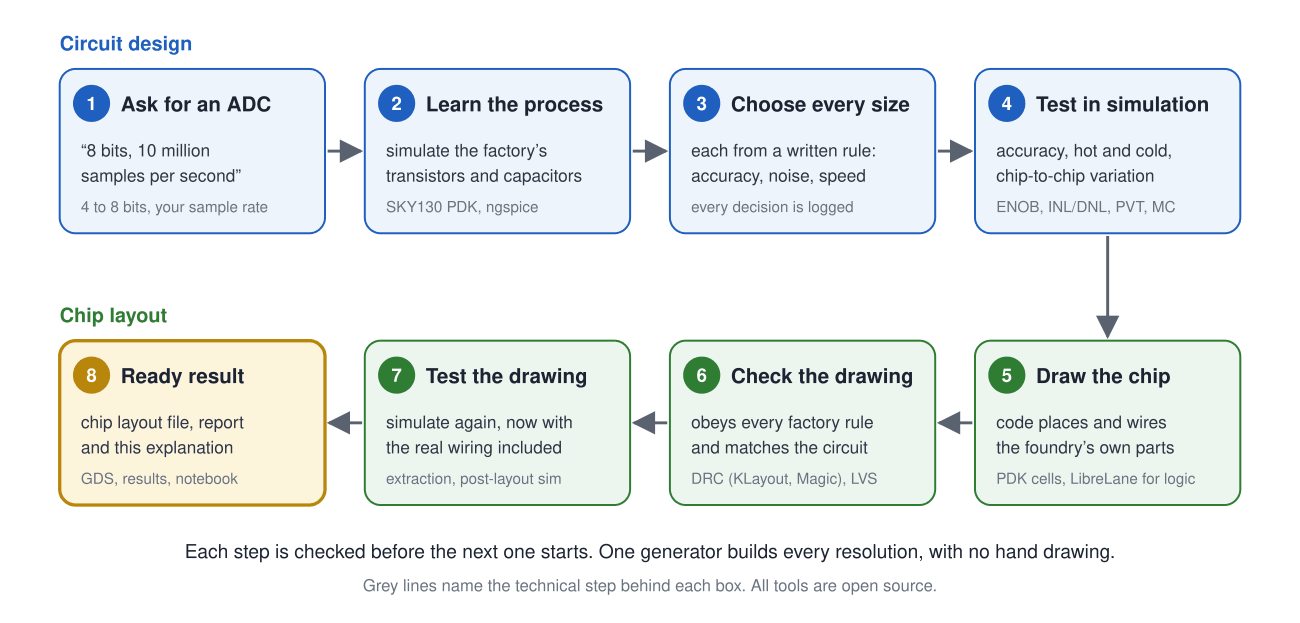

In [ ]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

def glance(p, width=950):
    p = Path(p)
    if p.exists():
        display(Image(filename=str(p), width=width))
    else:                       # Colab: the repository folder is opened by the setup cell below
        print(f"({p} is in the project folder; run the setup cell first)")

glance("docs/sargen_workflow.png")

**What it produced**: the same generator, unchanged, at 4, 6 and 8 bits. The table is computed from the result
files of sections 11 and 13: transistor-level simulation of each *extracted* layout against its schematic.

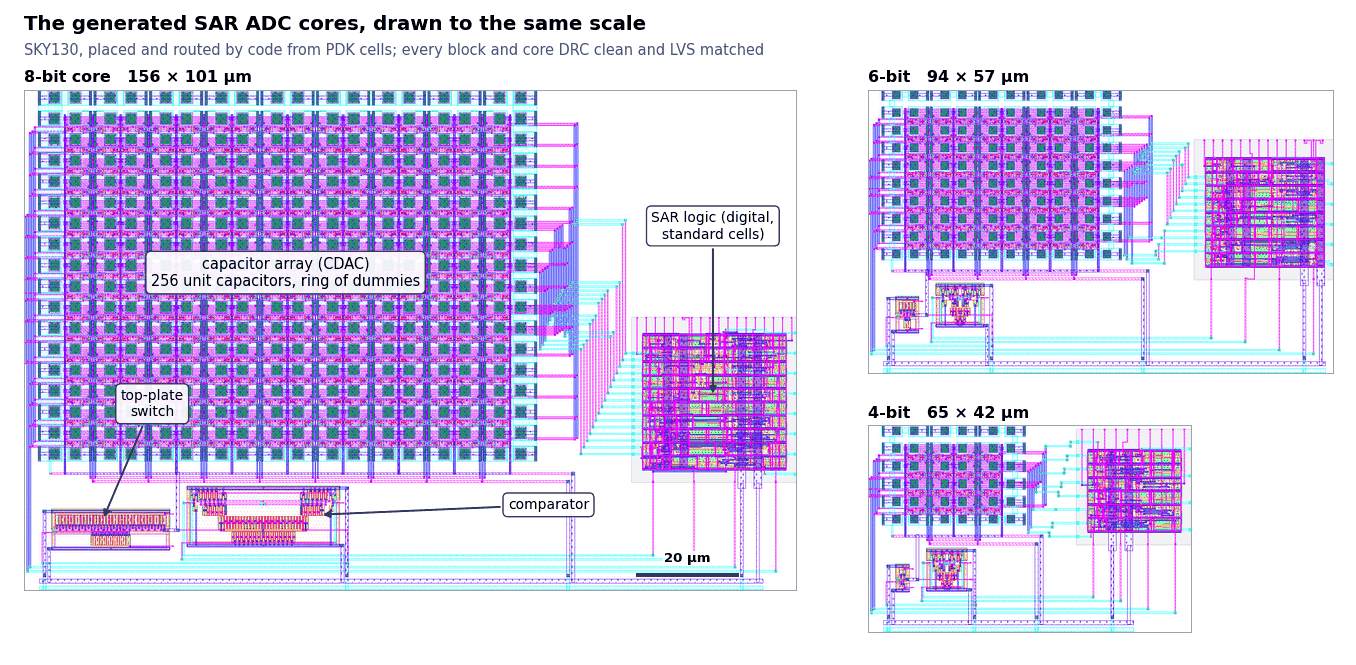

| resolution | core area | ENOB, schematic → layout | max DNL / INL, layout | power, layout | Walden FoM, layout |
|---|---|---|---|---|---|
| 4 bit | 2733 µm² | 3.96 → 3.98 | 0.04 / 0.02 LSB | 25 µW | 161 fJ/step |
| 6 bit | 5404 µm² | 6.01 → 6.02 | 0.05 / 0.07 LSB | 63 µW | 97 fJ/step |
| 8 bit | 15821 µm² | 7.98 → 7.98 | 0.25 / 0.29 LSB | 278 µW | 110 fJ/step |

In [ ]:
glance("docs/layouts_to_scale.png")
rows = ["| resolution | core area | ENOB, schematic → layout | max DNL / INL, layout | power, layout | Walden FoM, layout |",
        "|---|---|---|---|---|---|"]
for b in (4, 6, 8):
    pp = Path(f"results/{b}bit/layout/prepost.json")
    if not pp.exists():
        continue
    r = json.loads(pp.read_text())
    s, x = r["schematic"], r["full core from layout"]
    fs = json.loads(Path(f"results/{b}bit/summary.json").read_text())["spec"]["fs"]
    core = next(ln for ln in Path(f"results/{b}bit/layout/signoff.md").read_text().splitlines() if "core (all blocks" in ln)
    fom = x["p_uw"] * 1e-6 / (2 ** x["enob"] * fs) * 1e15
    rows.append(f"| {b} bit | {core.split('|')[3].strip()} µm² | {s['enob']:.2f} → {x['enob']:.2f} | "
                f"{x['dnl_t']:.2f} / {x['inl_t']:.2f} LSB | {x['p_uw']:.0f} µW | {fom:.0f} fJ/step |")
display(Markdown("\n".join(rows)))

All at 10 MS/s, 1.8 V and the typical corner; every block and core passes DRC (KLayout and Magic) and LVS (Netgen).
Layout keeps the schematic's accuracy; power rises with the wiring the logic drives (section 13). The 8-bit linearity
is resolved to 1/4 LSB (4 ramp points per code). Limits and open items are listed at the end.

## How to run
Everything uses open-source tools inside the **IIC-OSIC-TOOLS** container (tested with tag `2026.10`:
ngspice-47, Magic, Netgen, KLayout, SKY130A).

```bash
docker run -it --rm -p 127.0.0.1:8888:8888 -v $PWD:/foss/designs hpretl/iic-osic-tools:2026.10 -s jupyter lab
```
or, headless: `python3 run_flow.py --bits 4`. Python dependencies: numpy, matplotlib, pillow (all in the image).
A complete 4-bit run takes about 6 minutes on a 12-core laptop (simulations run in parallel).

**Google Colab:** run the next cell first. It installs ngspice (conda-forge) and the SKY130 PDK (`ciel`) in about
8 minutes and switches to a quicker test setting, because Colab has only 2 CPU cores. Locally it does nothing.

In [ ]:
# Google Colab only: installs ngspice (conda-forge) and the SKY130 PDK (ciel) - about 8 min, once per runtime.
# Locally (IIC-OSIC-TOOLS container) this cell does nothing.
import os, subprocess, sys

IN_COLAB = "google.colab" in sys.modules
REPO = "https://github.com/rajinthanr/sscs-ose-code-a-chip.github.io"
BRANCH = "sar-adc-generator"
PROJECT = "ISSCC27/submitted_notebooks/SAR_ADC_Generator"
SKY130_VERSION = "792ef67037d74c8c51811eab3ce23cf793491296"   # ciel sky130 build tested with this notebook

if IN_COLAB and not os.path.exists("/content/eda/bin/ngspice"):
    subprocess.run(["bash", "-c", f"""
        set -e; cd /content
        [ -d cac ] || (git clone -q --depth 1 --filter=blob:none --sparse -b {BRANCH} {REPO} cac &&
                       git -C cac sparse-checkout set {PROJECT})
        curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj bin/micromamba
        ./bin/micromamba create -y -q -p /content/eda -c conda-forge ngspice
        pip install -q ciel
        for i in 1 2 3; do   # retry: large downloads occasionally hit transient network errors
            ciel enable --pdk-family sky130 --pdk-root /content/pdk {SKY130_VERSION} && break
            [ $i = 3 ] && exit 1; sleep 15
        done
    """], check=True)
if IN_COLAB:
    os.environ["PATH"] = "/content/eda/bin:" + os.environ["PATH"]
    os.environ["PDK_ROOT"] = "/content/pdk"
    os.chdir(f"/content/cac/{PROJECT}")
QUICK = IN_COLAB      # Colab has 2 CPUs: fewer ramp hits / FFT points

## 1. Specification
Change `BITS` (4..8) and `FS` and re-run the notebook - every number below is regenerated.

In [ ]:
import json, os
from pathlib import Path
from IPython.display import Image, Markdown, display

from sargen import SarSpec
from sargen.flow import run_flow
from sargen.model import SarModel
from sargen.anim import animate_conversion
from sargen.sizing import sizing_table_md

BITS = 4          # resolution (4..8)
FS = 10e6         # sample rate [S/s]
spec = SarSpec(bits=BITS, fs=FS)
FLOW_OPTS = dict(hits=8, fft_n=64, mc_runs=300) if globals().get("QUICK") else {}
OUT = Path(f"build/{BITS}bit")
print(json.dumps(spec.to_dict(), indent=1))

{
 "bits": 4,
 "fs": 10000000.0,
 "vdd": 1.8,
 "vref": 1.8,
 "temp": 27.0,
 "corner": "tt",
 "dnl_3sigma_lsb": 0.5,
 "offset_3sigma_lsb": 1.0,
 "noise_lsb": 0.1,
 "settle_lsb": 0.25,
 "lsb": 0.1125,
 "vcm": 0.9,
 "cycles": 6,
 "fclk": 60000000.0
}


## 2. How a SAR ADC works - animated
The input is sampled on the bottom plates of a binary-weighted capacitor array while the top plate is held at
V<sub>cm</sub>. Afterwards the bottom plates are switched to V<sub>ref</sub> or ground one bit at a time
(MSB first). Charge conservation makes the top plate move by
$V_x - V_{cm} = \sum_i b_i\,\frac{C_i}{C_{tot}}V_{ref} - V_{in}$, so the comparator only has to decide the
*sign*: if the DAC voltage is still below V<sub>in</sub> the bit is kept, otherwise it is cleared.
After N decisions the bits are the binary code of V<sub>in</sub>.
The circuit SARGen generates (single-ended, bottom-plate sampling; source `docs/sar_architecture.svg`):

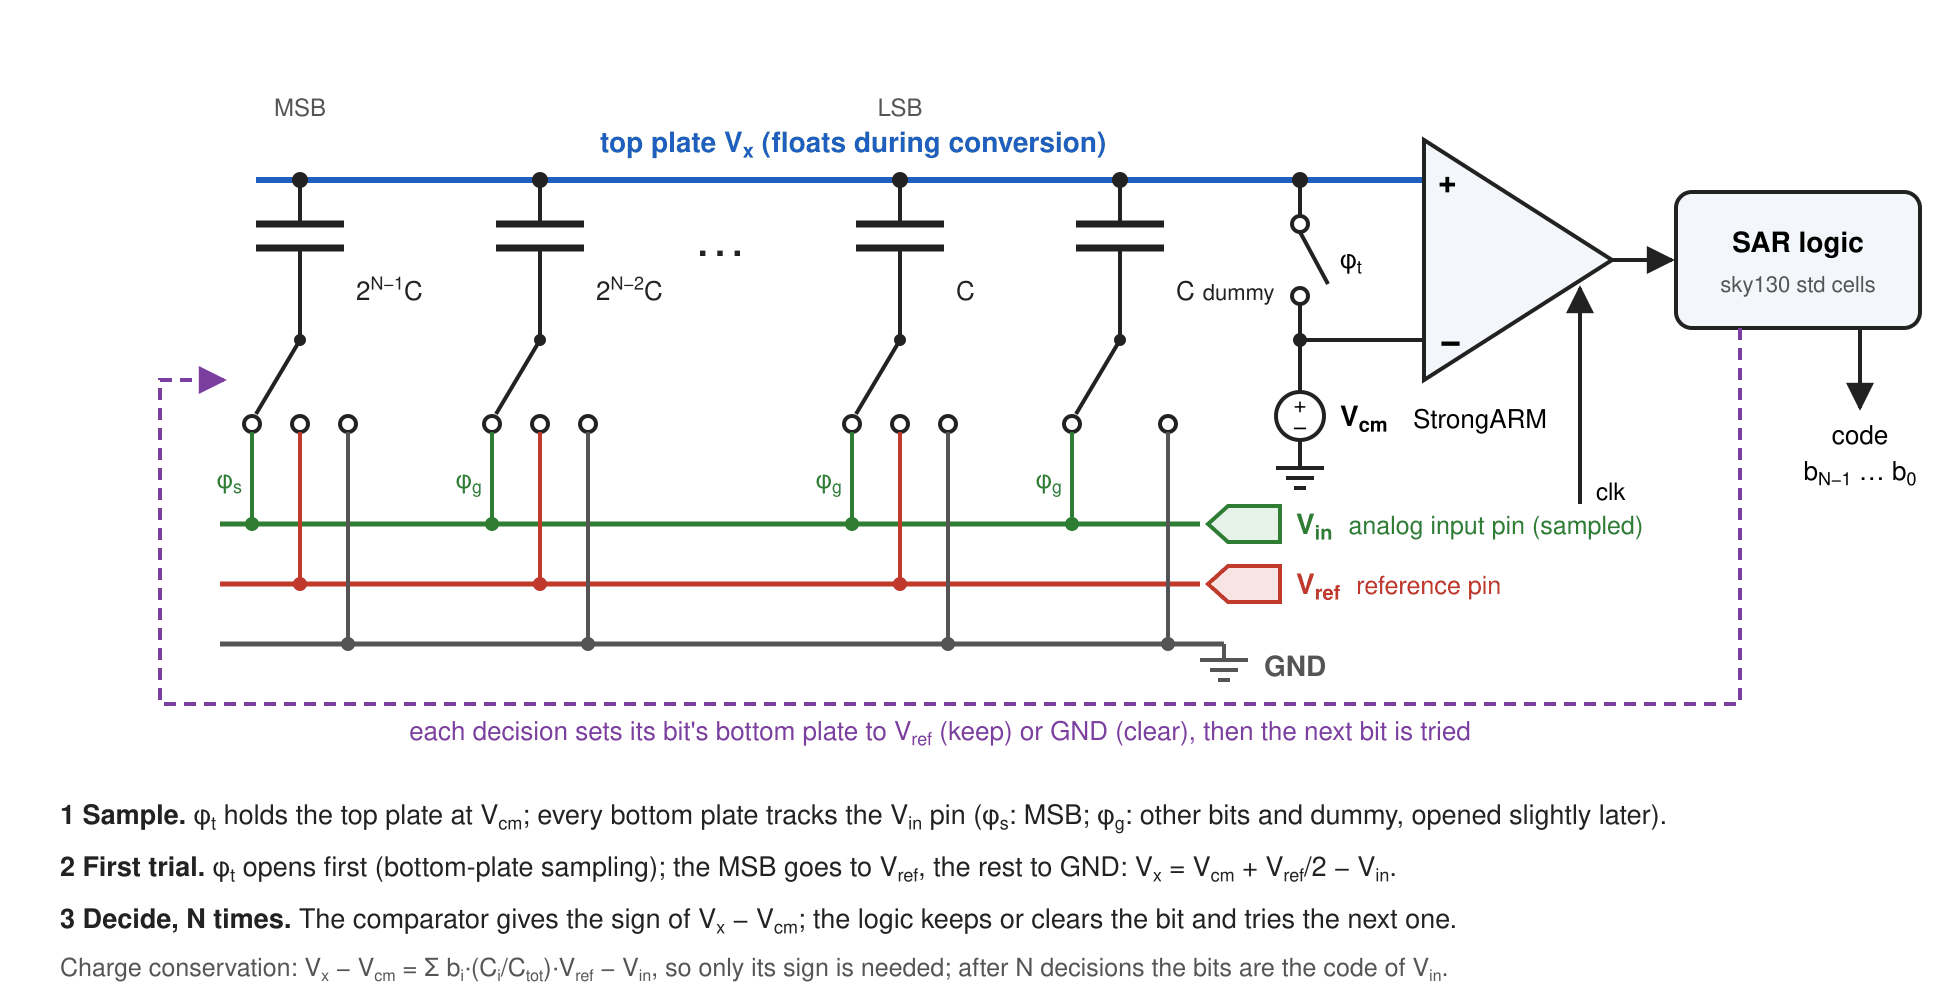

In [ ]:
display(Image(filename="docs/sar_architecture.png", width=900))

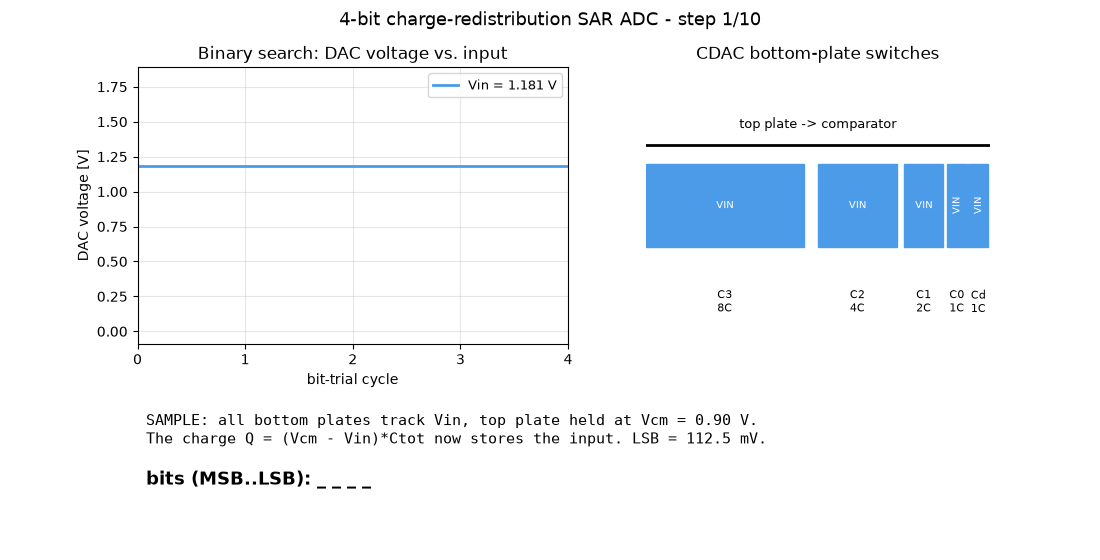

In [ ]:
OUT.mkdir(parents=True, exist_ok=True)
vin_demo = round(0.6 * 2**BITS) * spec.lsb + 0.5 * spec.lsb
animate_conversion(SarModel(BITS, spec.vref), vin_demo, OUT / "sar_animation.gif")
Image(filename=str(OUT / "sar_animation.gif"))

## 3. Run the automated flow
`run_flow` executes all stages; each is explained in the following sections.
PDK characterization is cached in `build/char/` after the first run.

In [ ]:
res = run_flow(spec, OUT, **FLOW_OPTS)

[   0.0s] 1/8 PDK characterization (A_VT, R_on, MIM)
[   0.0s] 2/8 sizing
[   0.0s] 3/8 netlist + single-conversion transient


[  55.9s] 4/8 comparator offset Monte Carlo (24 x 8 instances)


[ 226.0s] 5/8 ramp test: 32 hits/code, transistor level


[ 704.5s] 6/8 sine test: 128-point coherent FFT, transistor level


[ 885.9s] 7/8 mismatch Monte Carlo: behavioral model x 1000 (+0 SPICE seeds)


[ 887.1s] 8/8 animation + report


[ 891.1s] done -> build/4bit


## 4. PDK characterization (ngspice, SKY130 `tt` / `tt_mm`)
No textbook constants are used. The flow measures:
* **A<sub>VT</sub>**: 200 mismatch instances per geometry of diode-connected nfet/pfet in one netlist; A<sub>VT</sub> = sqrt(2) sigma(V<sub>GS</sub>) sqrt(WL).
* **R<sub>on</sub> x W** of transmission gates (worst case over the input range) and of the NMOS/PMOS DAC drivers -
  at nominal conditions *and* at the worst corners (ss/-40 C, ss/125 C, tt/-10 % supply). A standard-V<sub>t</sub> gate
  passing mid-rail at ss/-40 C is 36x weaker than at tt (both devices barely on), so the generator compares
  standard and **low-V<sub>t</sub>** (`nfet/pfet_01v8_lvt`) gates and picks the better one for the sampling switches.
* **MIM capacitance** per area and per perimeter (AC simulation of three geometries), and the **MIM matching
  coefficient** read from the PDK model card (`sigma(dC/C) = 2.8 %/sqrt(WL)`).

In [ ]:
c = res["char"]
display(Markdown(f'''
| quantity | value |
|---|---|
| A_VT nfet / pfet | {c["avt_n_mVum"]:.2f} / {c["avt_p_mVum"]:.2f} mV um |
| TG (Wn=1, Wp=2) R_on W, std, tt 27 C | {c["ron_tg_ohm_um"]/1e3:.2f} kOhm um |
| TG R_on W, worst corner: std / lvt | {c["ron_tg_worst_ohm_um"]["std"]/1e3:.1f} / {c["ron_tg_worst_ohm_um"]["lvt"]/1e3:.1f} kOhm um ({c["ron_worst_where"]["tg_std"]}) |
| NMOS / PMOS driver R_on W | {c["ron_n_ohm_um"]:.0f} / {c["ron_p_ohm_um"]:.0f} Ohm um |
| MIM density | {c["mim_ca_fF_um2"]:.3f} fF/um^2 + {c["mim_cp_fF_um"]:.3f} fF/um perimeter |
| MIM matching | {c["mim_match_pct_um"]} % um |
'''))


| quantity | value |
|---|---|
| A_VT nfet / pfet | 7.38 / 9.18 mV um |
| TG (Wn=1, Wp=2) R_on W, std, tt 27 C | 12.11 kOhm um |
| TG R_on W, worst corner: std / lvt | 434.9 / 7.4 kOhm um (ss -40C 1.80V) |
| NMOS / PMOS driver R_on W | 669 / 3095 Ohm um |
| MIM density | 2.000 fF/um^2 + 0.165 fF/um perimeter |
| MIM matching | 2.8 % um |


## 5. Specification-driven sizing
Each row is one design decision: the rule, the numbers that went in, and the result.

In [ ]:
design = json.loads((OUT / "design.json").read_text())
display(Markdown(sizing_table_md(design)))

| block | rule | numbers | result |
|---|---|---|---|
| spec | LSB = Vref / 2^N | 1.8 V / 16 | **112.50 mV** |
| timing | Tclk = 1 / ((N + 2) * fs) | fs = 10 MS/s, 6 cycles | **16.67 ns (60.0 MHz)** |
| CDAC | sigma_DNL(mid-code) = sqrt(2^N - 1) * sigma_u <= DNL_3sigma / 3 | sigma_u <= 4.303 %, A_C = 2.8 %um | **side >= 0.65 um (matching)** |
| CDAC | kT/C: sqrt(kT / C_total) <= noise_lsb * LSB | C_total >= 0.0327 fF | **negligible at this resolution** |
| CDAC | Cu = Ca * s^2 + Cp * 4s (characterized MIM) | s = 2.00 um, limited by min. size | **Cu = 9.32 fF, C_total = 149.1 fF** |
| comparator | offset only shifts the transfer curve here (no DNL/INL): spec = offset error | 3 sigma_os <= 1.0 LSB | **sigma_os <= 37.50 mV** |
| comparator | sigma_os ~ A_VT / sqrt(W L) <= offset_3sigma * LSB / 3 | A_VT = 7.38 mVum, target 37.50 mV | **W L >= 0.039 um^2 -> W/L = 2.0/0.3 (est. 9.52 mV)** |
| comparator | pre-amplifier needed if W L > 20 um^2 (input cap / kick-back) | W L = 0.04 um^2 | **no - StrongARM alone** |
| comparator | tail = 1.5 W_in, latch = W_in / 2, reset / inverters fixed |  | **tail 3.0, nlatch 1.0, platch 1.0 um** |
| sampling | TG device flavour = lowest worst-case R_on W (ss/-40C, ss/125C, tt/-10% supply) | std: 434.9 kOhm um, lvt: 7.4 kOhm um | **lvt transistors** |
| sampling | tau = T_track / ln(2^N / settle_lsb); 1/4 bit switch, 3/4 top switch | T_track = 14.17 ns, tau <= 3406 ps | **R_unit <= 91.4 kOhm, R_top <= 17136 Ohm** |
| sampling | W_n = (R_on W)_TG,worst / R  (Wp = 2 Wn), bit-i switch = 2^i units | worst (R_on W) = 7.45 kOhm um (ss -40C 1.80V) | **unit TG 0.45/0.90 um, top TG 0.45/0.90 um** |
| DAC driver | tau = 0.45 Tclk / ln(2^N / settle_lsb), per unit cap (binary scaled) | tau <= 1803 ps, R_unit <= 96.8 kOhm | **unit NMOS 0.45 um, unit PMOS 0.45 um** |

## 6. Generated netlist and a single conversion
The testbench below is written by `sargen.netlist`. The SAR logic is built from SKY130 standard cells
(`sky130_fd_sc_hd` DFF with reset, OR, NAND/NOR sized by fan-out); only the clock phases come from ideal sources.
Watch the top plate: it jumps with every bit trial and converges back to V<sub>cm</sub>, the binary search in silicon.

Three switching-order rules keep the top plate inside the supply rails, so no switch junction is ever
forward-biased (each one was found by the flow's own simulations, see the git history):
1. **MSB first:** when sampling ends, the MSB plate goes to V<sub>ref</sub> immediately.
2. **Track, then ground:** the other plates keep tracking V<sub>in</sub> until the MSB has settled and only then go to
   ground. Grounding them first pulled the top plate to V<sub>cm</sub> - V<sub>in</sub> (-0.85 V, 7 missing codes at 8 bit);
   letting them float instead pushed it to V<sub>cm</sub> + V<sub>ref</sub> - V<sub>in</sub> (2.6 V, INL bow).
3. **Release before set:** a rejected bit returns to ground (trial ends at 0.92 T<sub>clk</sub>, decision latched at
   0.80 T<sub>clk</sub>) before the next bit is tried; otherwise the top plate glitches by one bit weight every cycle.

* SAR ADC 4-bit testbench (generated by sargen)
.lib /foss/pdks/sky130A/libs.tech/ngspice/sky130.lib.spice tt
.include /foss/pdks/sky130A/libs.ref/sky130_fd_sc_hd/spice/sky130_fd_sc_hd.spice
.temp 27.0
.option method=gear
.subckt strongarm inp inn clk qp qn vdd vss
XMt tail clk vss vss sky130_fd_pr__nfet_01v8 L=0.15 W=3 nf=1 ad=0.87 as=0.87 pd=6.58 ps=6.58 nrd=0.09667 nrs=0.09667 sa=0 sb=0 sd=0 mult=1 m=1
XMi1 xp inp tail vss sky130_fd_pr__nfet_01v8 L=0.3 W=2 nf=1 ad=0.58 as=0.58 pd=4.58 ps=4.58 nrd=0.145 nrs=0.145 sa=0 sb=0 sd=0 mult=1 m=1
XMi2 xn inn tail vss sky130_fd_pr__nfet_01v8 L=0.3 W=2 nf=1 ad=0.58 as=0.58 pd=4.58 ps=4.58 nrd=0.145 nrs=0.145 sa=0 sb=0 sd=0 mult=1 m=1
XMn1 outn outp xp vss sky130_fd_pr__nfet_01v8 L=0.15 W=1 nf=1 ad=0.29 as=0.29 pd=2.58 ps=2.58 nrd=0.29 nrs=0.29 sa=0 sb=0 sd=0 mult=1 m=1
XMn2 outp outn xn vss sky130_fd_pr__nfet_01v8 L=0.15 W=1 nf=1 ad=0.29 as=0.29 pd=2.58 ps=2.58 nrd=0.29 nrs=0.29 sa=0 sb=0 sd=0 mult=1 m=1
XMp1 outn outp vdd vdd sky130_fd_pr__pf

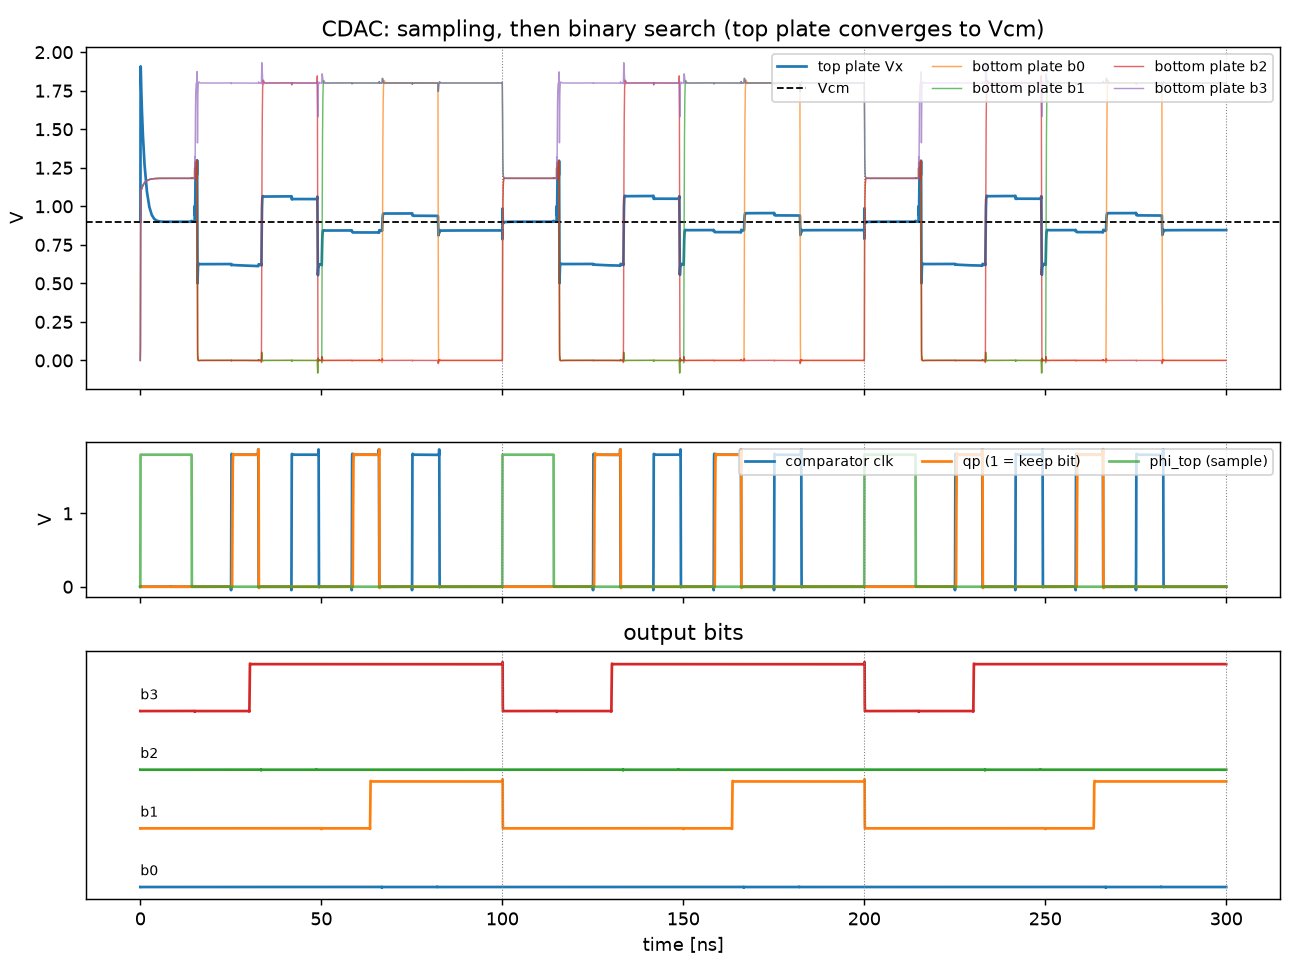

In [ ]:
tb = (OUT / f"sar_adc_{BITS}b_tb.spice").read_text().splitlines()
print("\n".join(tb[:12] + ["..."] + [l for l in tb if l.startswith(("* ----", "abr", "aff"))][:20]))
print(f"\nVin = {res['single']['vin']:.4f} V -> code {res['single']['code']} (ideal {res['single']['ideal']})")
Image(filename=str(OUT / "waveforms.png"))

## 7. Comparator offset Monte Carlo
192 StrongARM instances with independent SKY130 mismatch are swept with a slow ramp. In this single-ended,
conventional-switching SAR the comparator offset only shifts the whole transfer curve (offset error); it does
not create DNL. That is why a small, fast comparator is enough at low resolution.

sigma_os = 8.64 mV  (0.077 LSB), mean = 0.83 mV, n = 192


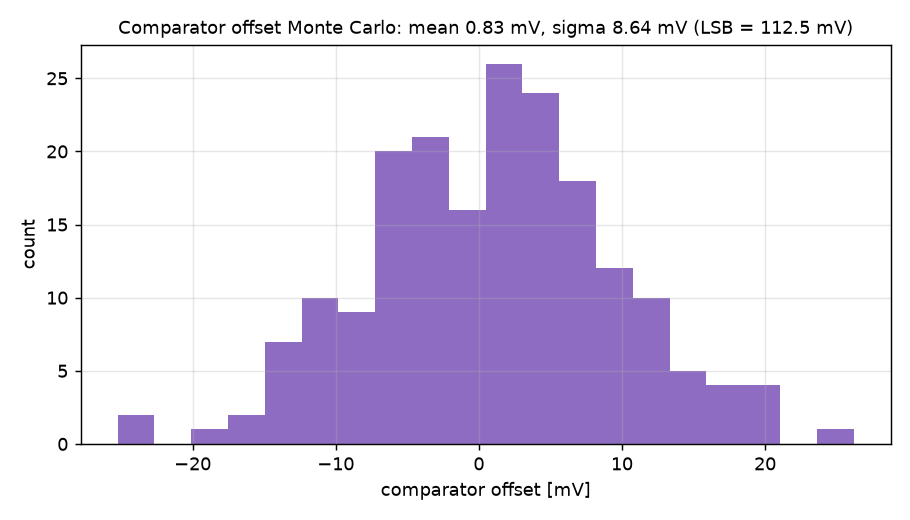

In [ ]:
o = res["comparator_offset"]
print(f"sigma_os = {o['sigma']*1e3:.2f} mV  ({o['sigma']/spec.lsb:.3f} LSB), mean = {o['mean']*1e3:.2f} mV, n = {o['n']}")
Image(filename=str(OUT / "comparator_offset.png"))

## 8. Static linearity: ramp + code-density (histogram) test
A slow ramp that slightly over-drives both ends is applied to the transistor-level ADC. The number of hits per
code gives DNL; its running sum gives INL (end-point fit).

max|DNL| = 0.038 LSB, max|INL| = 0.062 LSB, missing codes = 0, offset = -0.122 LSB, gain error = -0.021 LSB


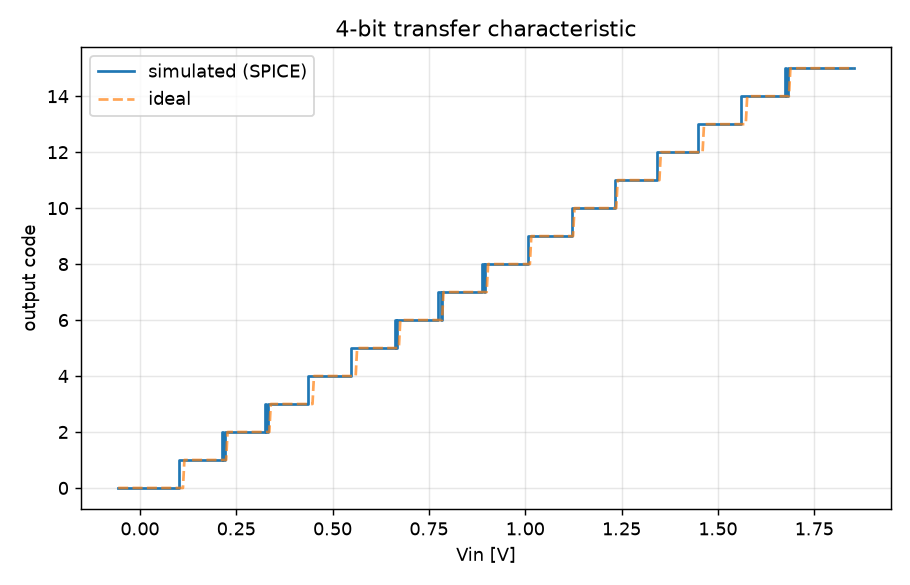

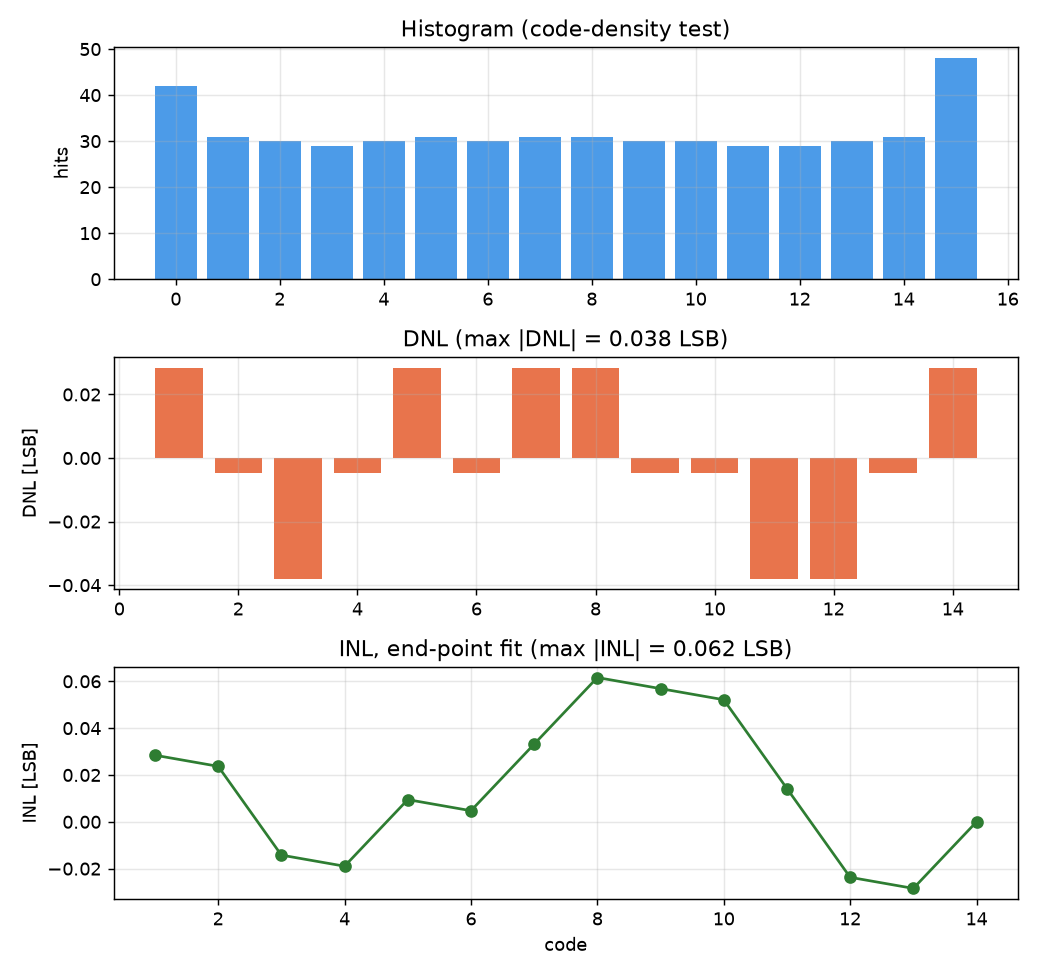

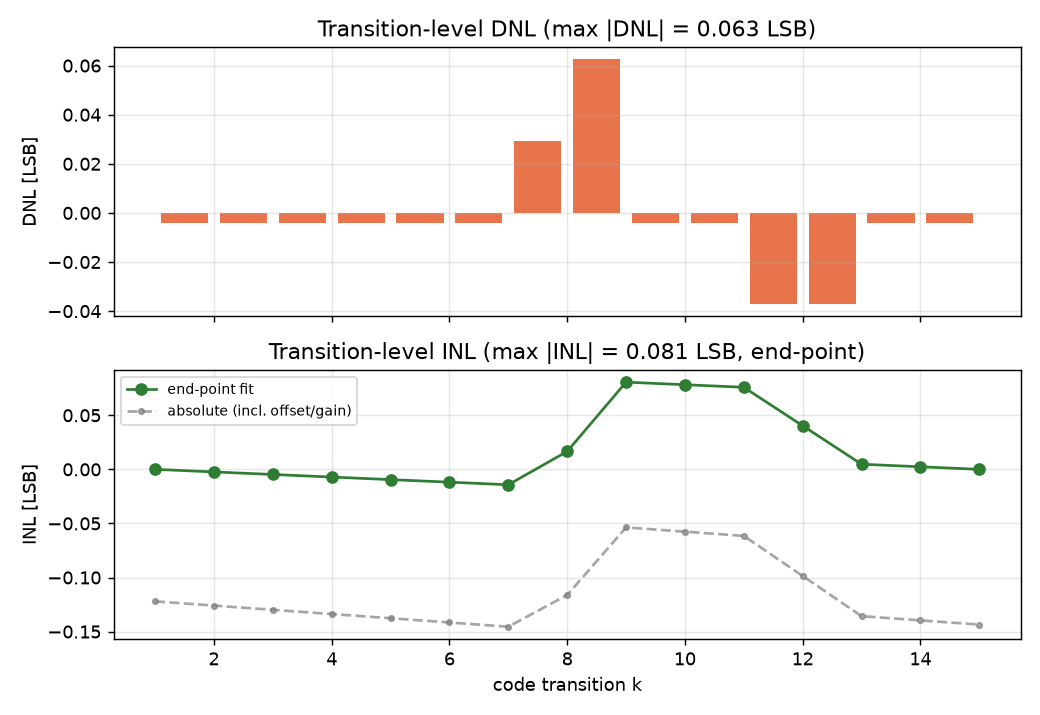

In [ ]:
s = res["static"]
print(f"max|DNL| = {s['dnl_max']:.3f} LSB, max|INL| = {s['inl_max']:.3f} LSB, missing codes = {s['missing_codes']}, "
      f"offset = {s['offset_lsb']:.3f} LSB, gain error = {s['gain_error_lsb']:.3f} LSB")
display(Image(filename=str(OUT / "transfer.png")))
display(Image(filename=str(OUT / "inl_dnl_histogram.png")))
Image(filename=str(OUT / "inl_dnl_transitions.png"))

## 9. Dynamic performance: coherent FFT, ENOB
A full-scale sine with a prime number of cycles in the record (coherent sampling, no window) is converted at
transistor level. ENOB = (SNDR - 1.76 dB) / 6.02.

SNDR 25.58 dB, SFDR 34.7 dB, ENOB 3.96 bit (ideal 4-bit quantizer on the same samples: 3.97 bit)
Power 13.93 uW, 1.393 pJ/conv, Walden FoM 89.7 fJ/conv-step


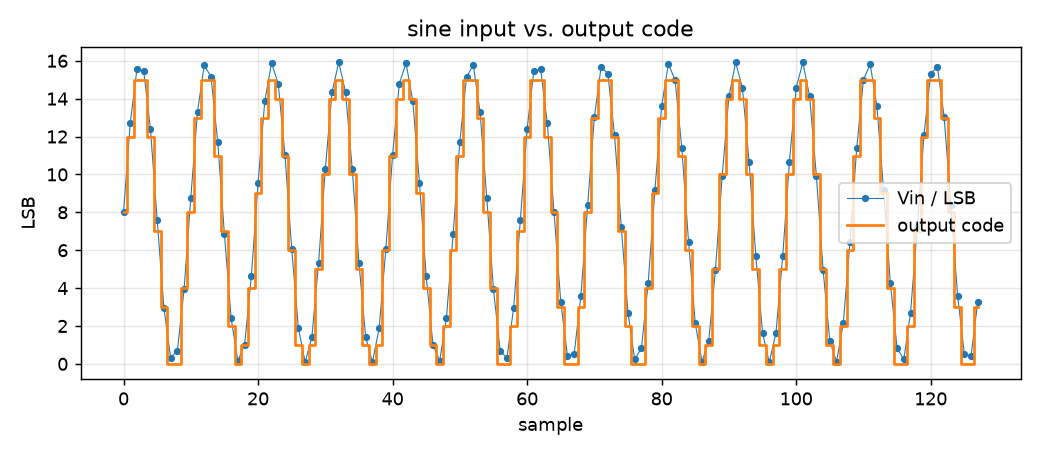

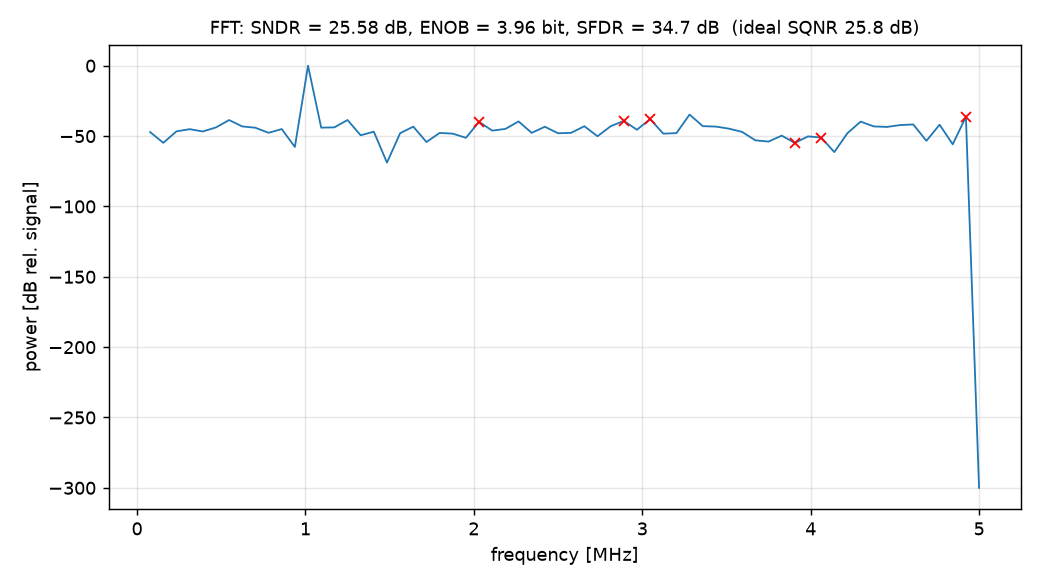

In [ ]:
d, p = res["dynamic"], res["power"]
print(f"SNDR {d['sndr_db']:.2f} dB, SFDR {d['sfdr_db']:.1f} dB, ENOB {d['enob']:.2f} bit "
      f"(ideal {BITS}-bit quantizer on the same samples: {d['ideal_model_enob']:.2f} bit)")
print(f"Power {p['p_total']*1e6:.2f} uW, {p['energy_per_conv']*1e12:.3f} pJ/conv, Walden FoM {p['walden_fom_J']*1e15:.1f} fJ/conv-step")
display(Image(filename=str(OUT / "sine_samples.png")))
Image(filename=str(OUT / "fft.png"))

## 10. Yield: PDK-calibrated behavioral Monte Carlo
The behavioral model uses the *measured* unit-capacitor sigma (from the PDK MIM model) and comparator offset
sigma (section 7), so thousands of mismatch samples run in seconds.

1000 runs: 99th percentile DNL 0.130 LSB, INL 0.083 LSB, yield(DNL<0.5 LSB) = 100.0 %


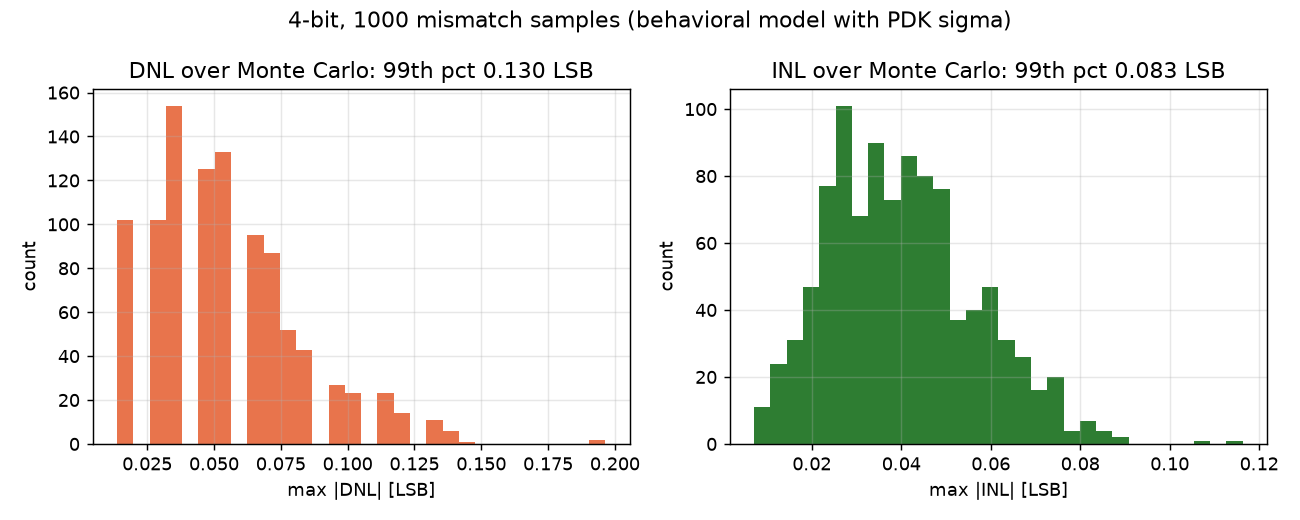

In [ ]:
m = res["mc"]
print(f"{m['runs']} runs: 99th percentile DNL {m['dnl_p99']:.3f} LSB, INL {m['inl_p99']:.3f} LSB, "
      f"yield(DNL<0.5 LSB) = {m['yield_dnl_lt_0p5']*100:.1f} %")
Image(filename=str(OUT / "mc_linearity.png"))

## 11. One generator, 4 to 8 bits
The same code sized and simulated 4-, 6- and 8-bit converters at transistor level (8-bit: 2048-point ramp,
256-point FFT, about an hour on 11 cores). These long runs are not repeated inside the notebook; their small
result files live in `results/` and are regenerated with `python3 run_flow.py --bits N` and
`python3 collect_results.py`.

What changes with N is driven by the sizing rules: the unit capacitor grows once **MIM matching** (not kT/C) limits
mid-code DNL, the comparator input pair grows with the tighter offset target, and the top-plate switch grows with the
total array capacitance.

| bits | fs | enob | ideal_enob | sndr | dnl | inl | missing | offset | p_uw | e_pj | fom_fj | ctot_ff | cu_ff | w_in | mc_dnl_p99 | runtime_min |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 4 | 1e+07 | 3.96 | 3.97 | 25.6 | 0.0625 | 0.0806 | 0 | -0.122 | 13.9 | 1.39 | 89.7 | 149 | 9.32 | 2 | 0.13 | 6.16 |
| 6 | 1e+07 | 6.01 | 6.14 | 37.9 | 0.206 | 0.202 | 0 | -0.262 | 33.8 | 3.38 | 52.5 | 596 | 9.32 | 2.1 | 0.302 | 17.7 |
| 8 | 1e+07 | 7.94 | 8.05 | 49.6 | 0.129 | 0.224 | 0 | -0.81 | 187 | 18.7 | 76 | 4.19e+03 | 16.4 | 33.1 | 0.443 | 61.3 |


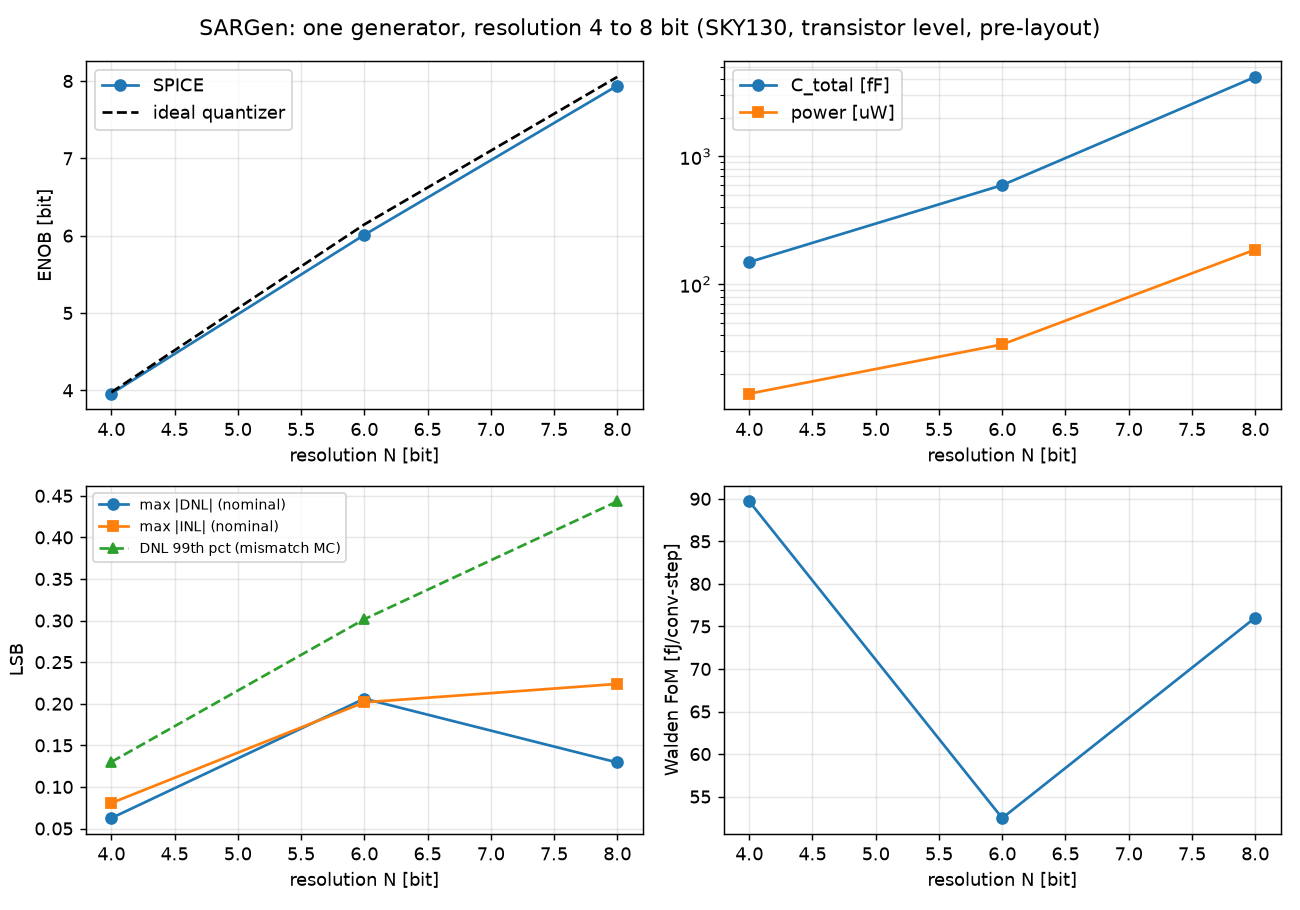

In [ ]:
R = Path("results")
def show(p):
    p = Path(p)
    if p.suffix == ".png" and p.exists():
        display(Image(filename=str(p)))
    elif p.exists():
        display(Markdown(p.read_text()))
    else:
        print(f"({p} not generated yet)")
show(R / "scaling.md")
show(R / "scaling.png")

## 12. Robustness of the nominal 4-bit design
One **fixed** design (sized at `tt`, 27 C, 1.8 V) is re-simulated - not re-sized - across conditions.

**12a. Process corners x temperature x supply**

| point | corner | temp | vdd | enob | sndr_db | sfdr_db | f_in | dnl_max | inl_max | missing | dnl_t | inl_t | offset_lsb | gain_lsb | p_uw |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| tt -40C 1.80V | tt | -40 | 1.8 | 3.97 | 25.7 | 35.9 | 1.02e+06 | 0.0667 | 0.0667 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 13.5 |
| tt +27C 1.80V | tt | 27 | 1.8 | 3.96 | 25.6 | 34.7 | 1.02e+06 | 0.0711 | 0.0995 | 0 | 0.129 | 0.0996 | -0.139 | 0.0117 | 13.9 |
| tt +125C 1.80V | tt | 125 | 1.8 | 3.97 | 25.7 | 35.9 | 1.02e+06 | 0 | 0 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 15.9 |
| ss -40C 1.80V | ss | -40 | 1.8 | 3.98 | 25.7 | 37 | 1.02e+06 | 0.0616 | 0.0569 | 0 | 0.0625 | 0.0569 | -0.0723 | 0.0117 | 13.6 |
| ss +27C 1.80V | ss | 27 | 1.8 | 3.97 | 25.7 | 36.9 | 1.02e+06 | 0.0667 | 0.0667 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 14 |
| ss +125C 1.80V | ss | 125 | 1.8 | 3.98 | 25.7 | 36.4 | 1.02e+06 | 0.0616 | 0.0616 | 0 | 0.0625 | 0.0617 | -0.0723 | 0.0117 | 14.8 |
| ff -40C 1.80V | ff | -40 | 1.8 | 3.97 | 25.7 | 35.9 | 1.02e+06 | 0.0667 | 0.0667 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 13.3 |
| ff +27C 1.80V | ff | 27 | 1.8 | 3.99 | 25.8 | 36.7 | 1.02e+06 | 0 | 0 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 14.5 |
| ff +125C 1.80V | ff | 125 | 1.8 | 3.96 | 25.6 | 35 | 1.02e+06 | 0.183 | 0.183 | 0 | 0.195 | 0.185 | -0.271 | 0.145 | 23.5 |
| sf -40C 1.80V | sf | -40 | 1.8 | 3.96 | 25.6 | 33.9 | 1.02e+06 | 0 | 0 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 13.4 |
| sf +27C 1.80V | sf | 27 | 1.8 | 3.97 | 25.6 | 34.8 | 1.02e+06 | 0 | 0 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 14.1 |
| sf +125C 1.80V | sf | 125 | 1.8 | 3.98 | 25.7 | 34.7 | 1.02e+06 | 0.0667 | 0.0667 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 15 |
| fs -40C 1.80V | fs | -40 | 1.8 | 3.97 | 25.7 | 35.7 | 1.02e+06 | 0.123 | 0.113 | 0 | 0.129 | 0.104 | -0.139 | 0.145 | 13.5 |
| fs +27C 1.80V | fs | 27 | 1.8 | 3.98 | 25.7 | 37.7 | 1.02e+06 | 0.128 | 0.128 | 0 | 0.129 | 0.128 | -0.139 | 0.0117 | 15.9 |
| fs +125C 1.80V | fs | 125 | 1.8 | 3.95 | 25.5 | 35.6 | 1.02e+06 | 0.237 | 0.279 | 0 | 0.262 | 0.285 | -0.404 | 0.277 | 31.1 |
| tt +27C 1.62V | tt | 27 | 1.62 | 3.98 | 25.7 | 37.4 | 1.02e+06 | 0.133 | 0.133 | 0 | 0.137 | 0.133 | -0.00586 | -0.0547 | 11.2 |
| tt +27C 1.98V | tt | 27 | 1.98 | 3.97 | 25.7 | 35.5 | 1.02e+06 | 0 | 0 | 0 | 0.00391 | 1.47e-15 | -0.0723 | -0.0547 | 17.3 |


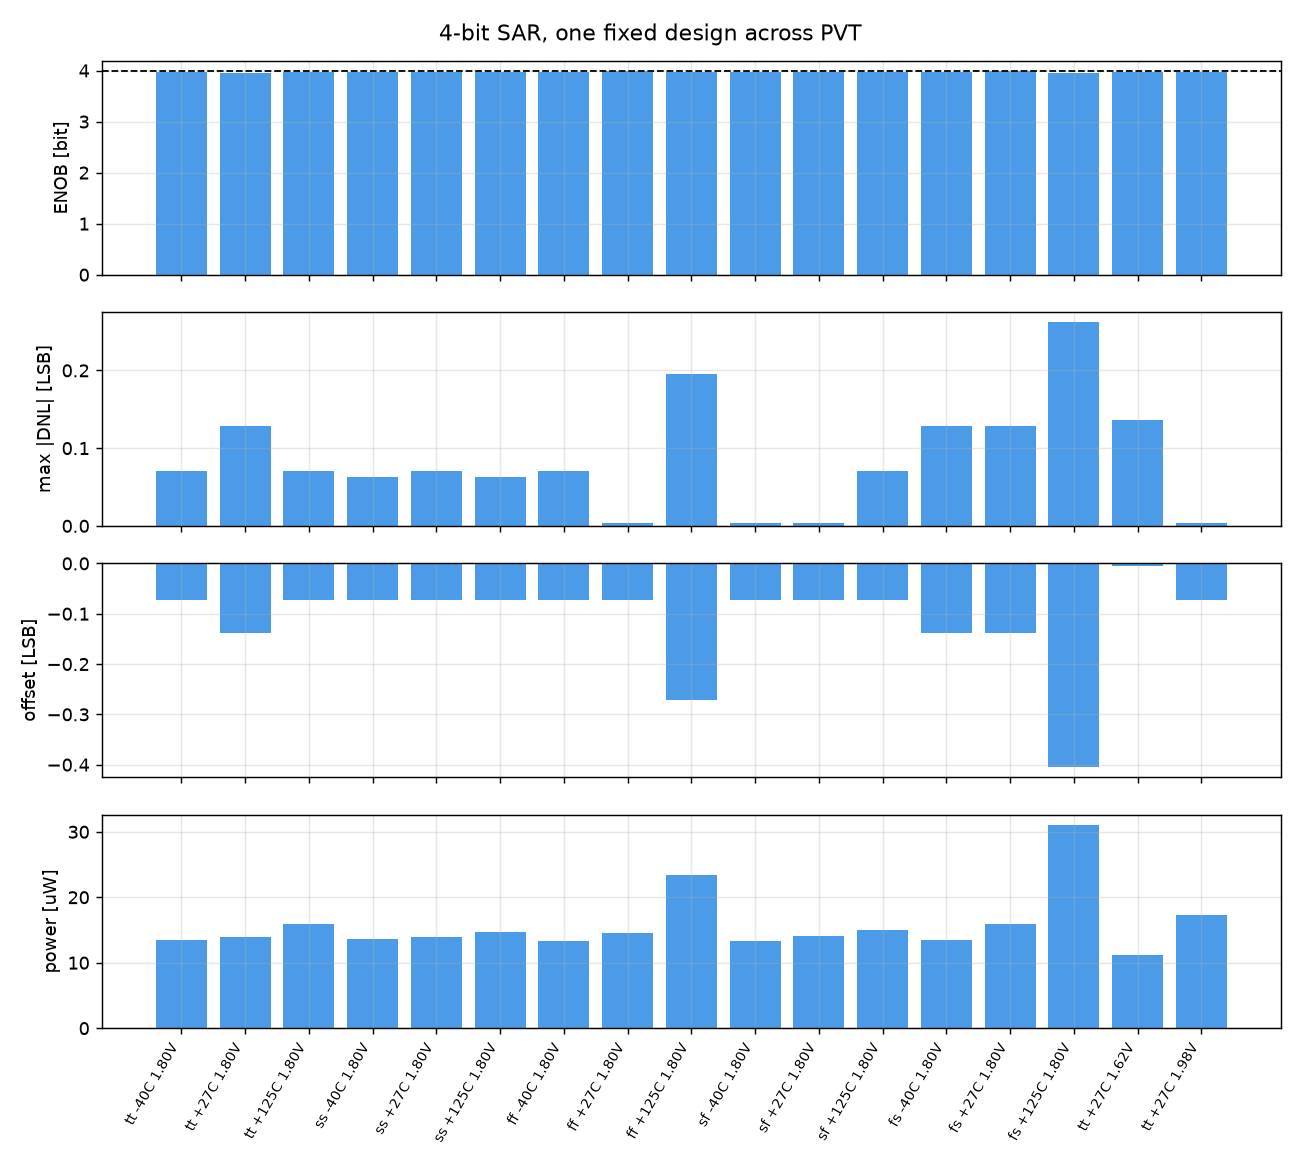

In [ ]:
show(R / "4bit/sweeps/pvt_4b.md")
show(R / "4bit/sweeps/pvt_4b.png")

**12b. Input frequency up to Nyquist** - sampling-switch non-linearity would show up as falling ENOB.

In [ ]:
show(R / "4bit/sweeps/fin_4b.md")

| point | f_in | enob | sndr_db | sfdr_db |
|---|---|---|---|---|
| fin=0.023 fs | 2.34e+05 | 3.95 | 25.5 | 35.9 |
| fin=0.102 fs | 1.02e+06 | 3.96 | 25.6 | 34.7 |
| fin=0.242 fs | 2.42e+06 | 3.99 | 25.8 | 37 |
| fin=0.367 fs | 3.67e+06 | 3.95 | 25.5 | 35.4 |
| fin=0.461 fs | 4.61e+06 | 3.94 | 25.5 | 36.4 |
| fin=0.492 fs | 4.92e+06 | 3.97 | 25.6 | 36.6 |


**12c. Sample rate** - the same design clocked faster until settling or comparator time runs out.

In [ ]:
show(R / "4bit/sweeps/fs_4b.md")

| point | fs | enob | sndr_db | sfdr_db | f_in | dnl_max | inl_max | missing | dnl_t | inl_t | offset_lsb | gain_lsb | p_uw |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 10 MS/s | 1e+07 | 3.96 | 25.6 | 34.7 | 1.02e+06 | 0.0711 | 0.0995 | 0 | 0.129 | 0.0996 | -0.139 | 0.0117 | 13.9 |
| 20 MS/s | 2e+07 | 3.97 | 25.6 | 36.5 | 2.03e+06 | 0.0711 | 0.0995 | 0 | 0.0703 | 0.0996 | -0.139 | 0.0117 | 27.9 |
| 40 MS/s | 4e+07 | 3.99 | 25.8 | 37.3 | 4.06e+06 | 0.0667 | 0.0667 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 56.2 |
| 80 MS/s | 8e+07 | 3.86 | 25 | 31.6 | 8.12e+06 | 0.0711 | 0.0806 | 0 | 0.0703 | 0.0427 | -0.0723 | 0.0117 | 114 |
| 160 MS/s | 1.6e+08 | nan | nan | nan | 1.62e+07 | nan | nan | 14 | nan | nan | nan | nan | 206 |


**12d. Comparator regeneration** - clock-to-output delay grows as tau * ln(1/dV) for small inputs; this sets the
metastability margin of the bit cycle.

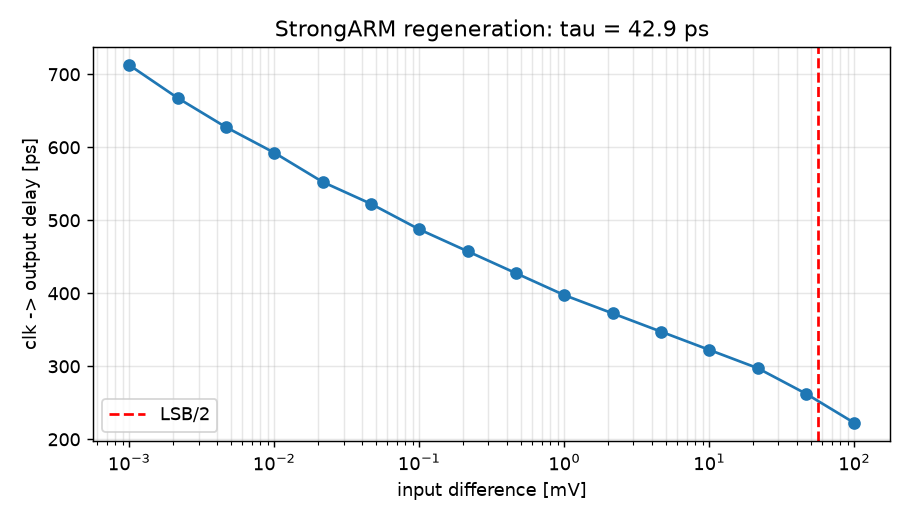

In [ ]:
show(R / "4bit/sweeps/cmp_delay_4b.png")

**12e. Transistor-level mismatch vs. the behavioral model** - full SPICE ramps with SKY130 mismatch (`tt_mm`)
compared with the PDK-calibrated behavioral Monte Carlo of section 10 (red lines: individual transistor-level dies).

*Pitfall worth knowing:* each ramp is split into parallel ngspice runs. `set rndseed` in `.spiceinit` does **not**
give the same mismatch draws in every process, so the chunks silently became different dies and the stitched
transfer curve showed fake DNL steps exactly at the chunk boundaries. `.option seed=N` in the netlist is
reproducible; `sargen.spice` injects it.

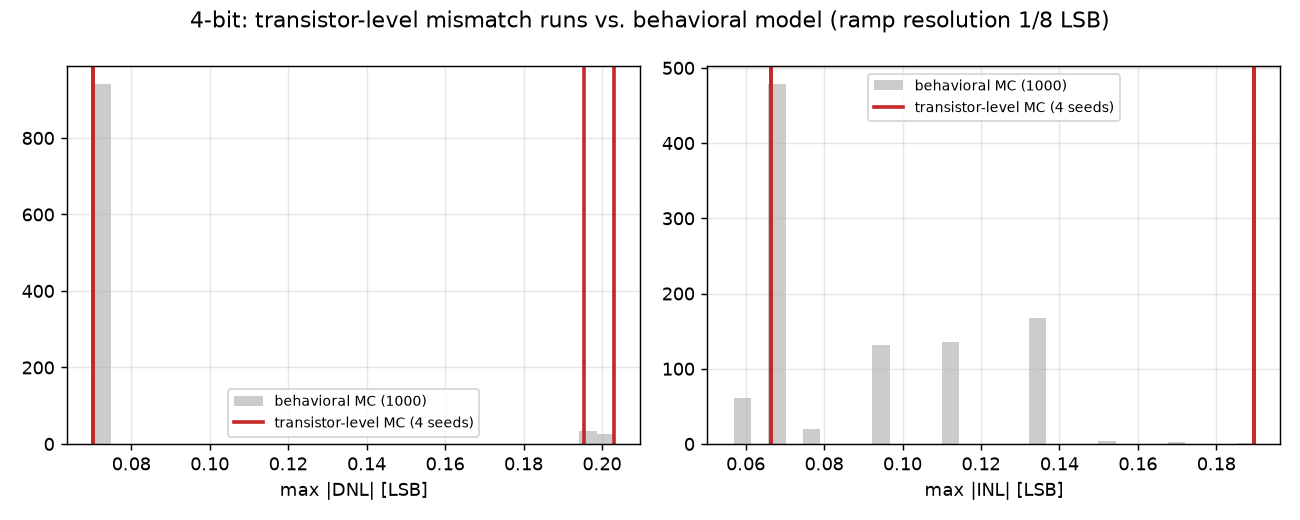

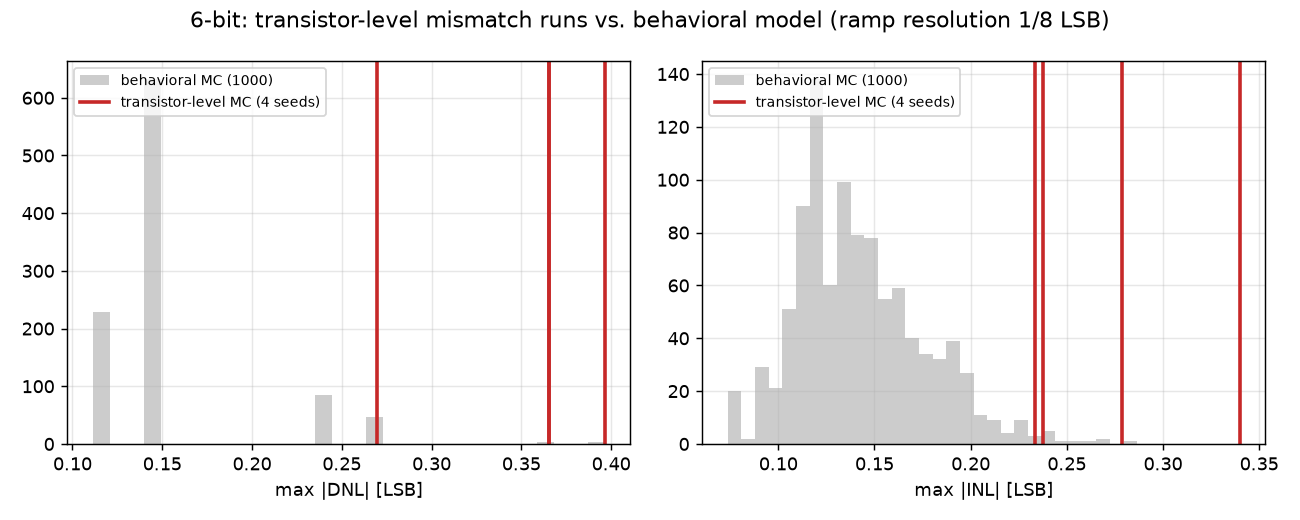

In [ ]:
for n in (4, 6):
    show(R / f"{n}bit/sweeps/spice_mc_{n}b.png")

## 13. Automated layout and post-layout verification
Every block is generated by code, from the **SKY130 PDK's own PCells** (Magic's device generator: MIM capacitor and
FETs are correct by construction); SARGen only places and routes them, packing to the real layer extents and the
design rules. Each block is closed at **DRC 0 / LVS match** before the next one is built (KLayout `sky130A_mr.drc`
plus a deck for rule capm.10, Magic DRC, Netgen LVS), and the analog blocks are re-simulated from their extracted
layout. What shaped the layout (details and numbers: `docs/layout_findings.md`):

* **CDAC unit cell** - one 2 x 2 um MIM cap with its *own* switches. SKY130 rule **capm.10** keeps diffusion, poly, li
  and met1 out from under a MIM cap, so the switches sit in the 1.34 um gap that rule capm.11 forces between caps;
  only met2 control rails pass under the cap, whose bottom plate shields the top plate. The cell (4.88 x 3.58 um
  pitch) is set by the capacitor spacing rules, not by the switch. No met5 (TinyTapeout power grid).
* **CDAC array** - every bit is built from point-symmetric unit pairs (common centroid), packed with at most 3 bits per
  row so one unit cell serves every resolution; a ring of dummy unit caps gives every real unit real neighbours.
  Extracted top-plate coupling of all control rails: 0.6 % of the array, systematic bit-weight error < 0.04 %.
* **StrongARM - one generator for 4 to 8 bits** - mirror symmetry with the tail and clock on the axis, a clustered
  input pair with identical inner drains (equal capacitance on the integration nodes), dummy fingers, guard rings,
  output tracks swapped on the axis and balanced on extraction, standard-Vt devices (better matching): 1671 -> ~90 um^2
  at 4 bit. The sizing sets the device widths and the generator derives the fingers (input pair, tail, latch, trim),
  so the 8-bit comparator - a 14-finger input pair - comes from the same code. A common-centroid (ABBA) pair was tried
  at 8 bit and dropped: on extraction it unbalances the integration nodes (xp / xn 1.1 %), while the clustered mirrored
  pair keeps them within 0.5 % and the outputs within 0.3 % at every resolution.
* **Top-plate switch** in closed p+ / n-tap guard rings: its diffusion is the floating top plate's only junction.
  Three source/drain tracks (NMOS vcm, shared top, PMOS vcm) let it scale to any finger count (17 + 34 at 8 bit).
* **SAR logic** - the same standard cells as the netlist, hardened with **LibreLane** (tap cells, decaps, met4-only power),
  re-checked by the same signoff.
* **Core** - analog on the west, logic on the east; the top-plate net is met4 only and runs along no dynamic line.

To regenerate (inside IIC-OSIC-TOOLS, with the pinned layout environment of `layout/setup_env.sh`):
```bash
for n in 4 6 8; do
  for b in unitcell cdacu comparator topsw sarlogic; do python run_layout.py $b --bits $n; done
  python run_layout.py cdacu --bits $n --pex; python run_layout.py comparator --bits $n --pex
  python run_layout.py core --bits $n --pex          # place + route the blocks above, DRC / LVS, extraction
  python collect_layout.py $n
done
python run_postlayout.py --bits 4                    # cases whose extractions exist
```
The same generators, unchanged, build the 6- and 8-bit cores: only the design (`build/<N>bit/design.json`) differs.

| block | size [um] | area [um^2] | KLayout DRC (incl. capm.10) | magic DRC | LVS |
|---|---|---|---|---|---|
| CDAC unit cell (MIM cap + its own switches) | 5.60 x 4.62 | 26 | 0 | 0 | match (5/5 devices) |
| unit-cell abutment test (2 x 3) | 15.92 x 11.41 | 182 | 0 | 0 | match (30/30 devices) |
| 4-bit CDAC (common-centroid, dummy-cap ring) | 36.02 x 24.26 | 874 | 0 | 0 | match (81/81 devices) |
| StrongARM comparator | 9.87 x 8.79 | 87 | 0 | 0 | match (18/18 devices) |
| top-plate sampling switch (guard rings) | 4.45 x 5.77 | 26 | 0 | 0 | match (2/2 devices) |
| SAR logic (LibreLane, sky130_fd_sc_hd) | 23.40 x 23.40 | 548 | 0 | 0 | match (22/22 devices) |
| 4-bit SAR ADC core (all blocks routed) | 65.42 x 41.78 | 2733 | 0 | 0 | match (4/4 block instances) |


cdac_unit


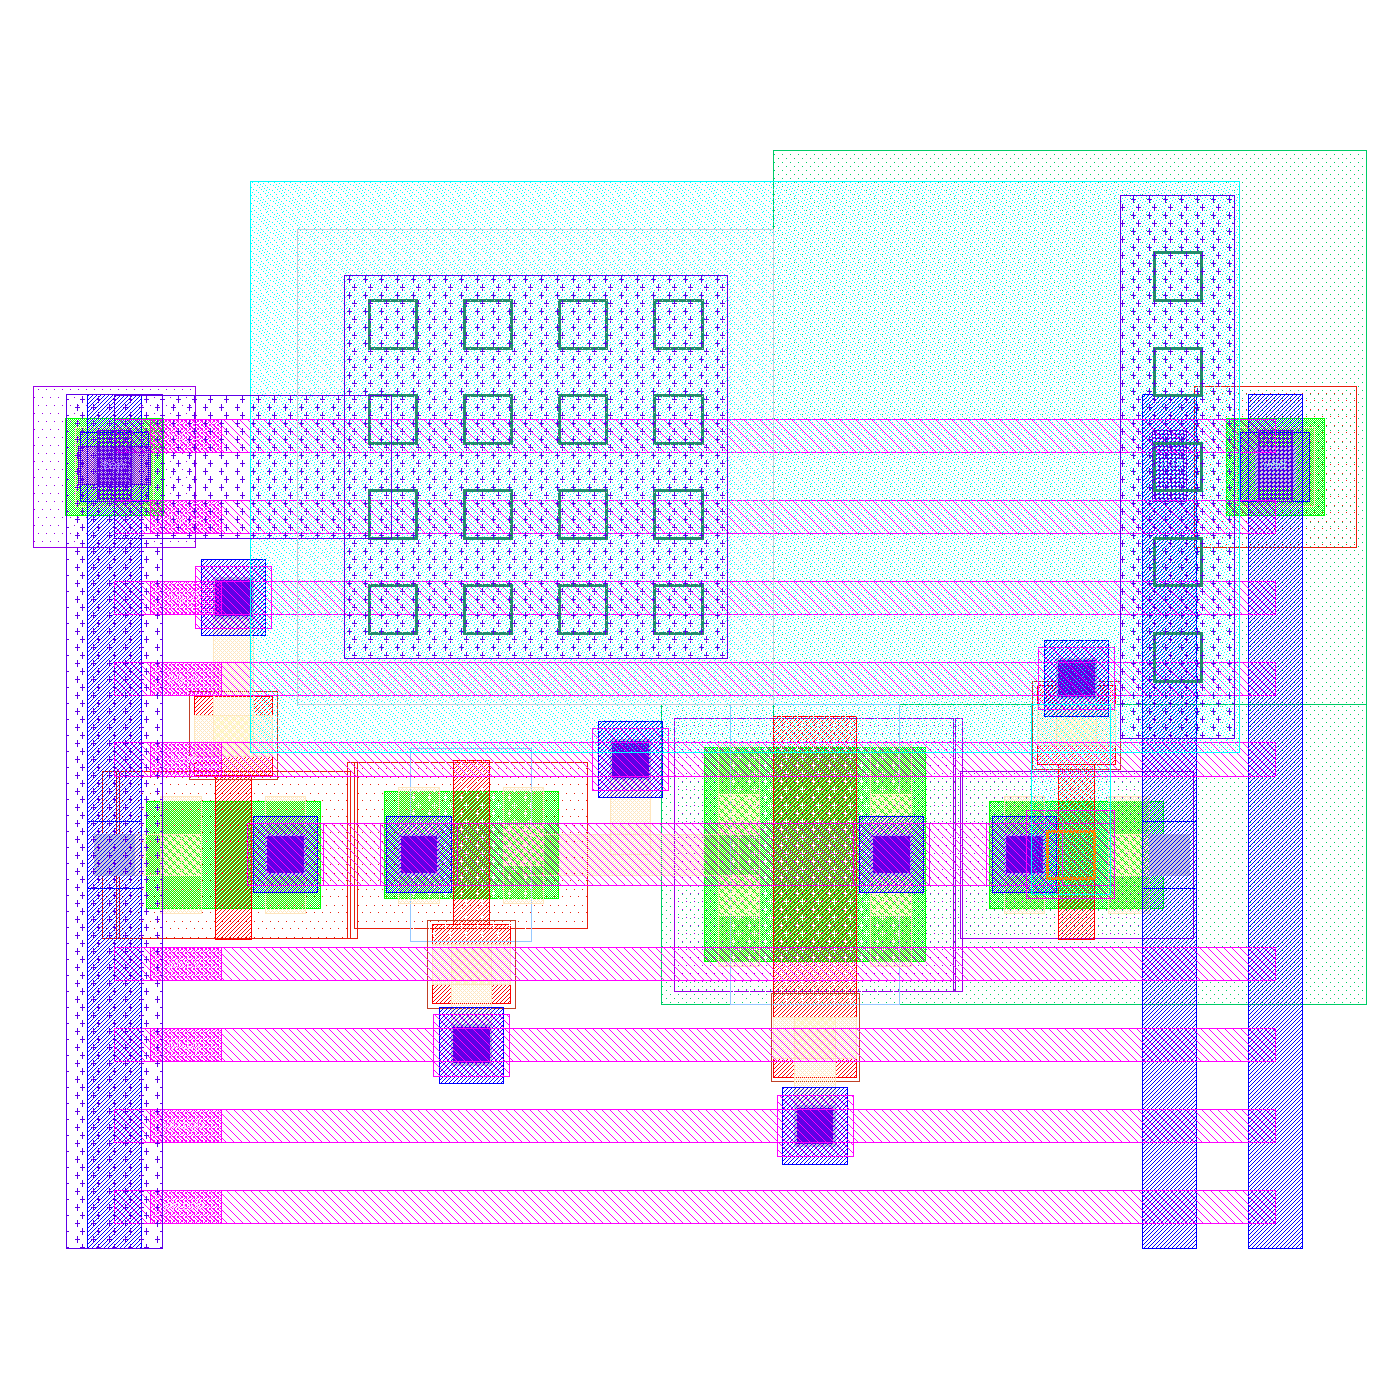

cdacu4b


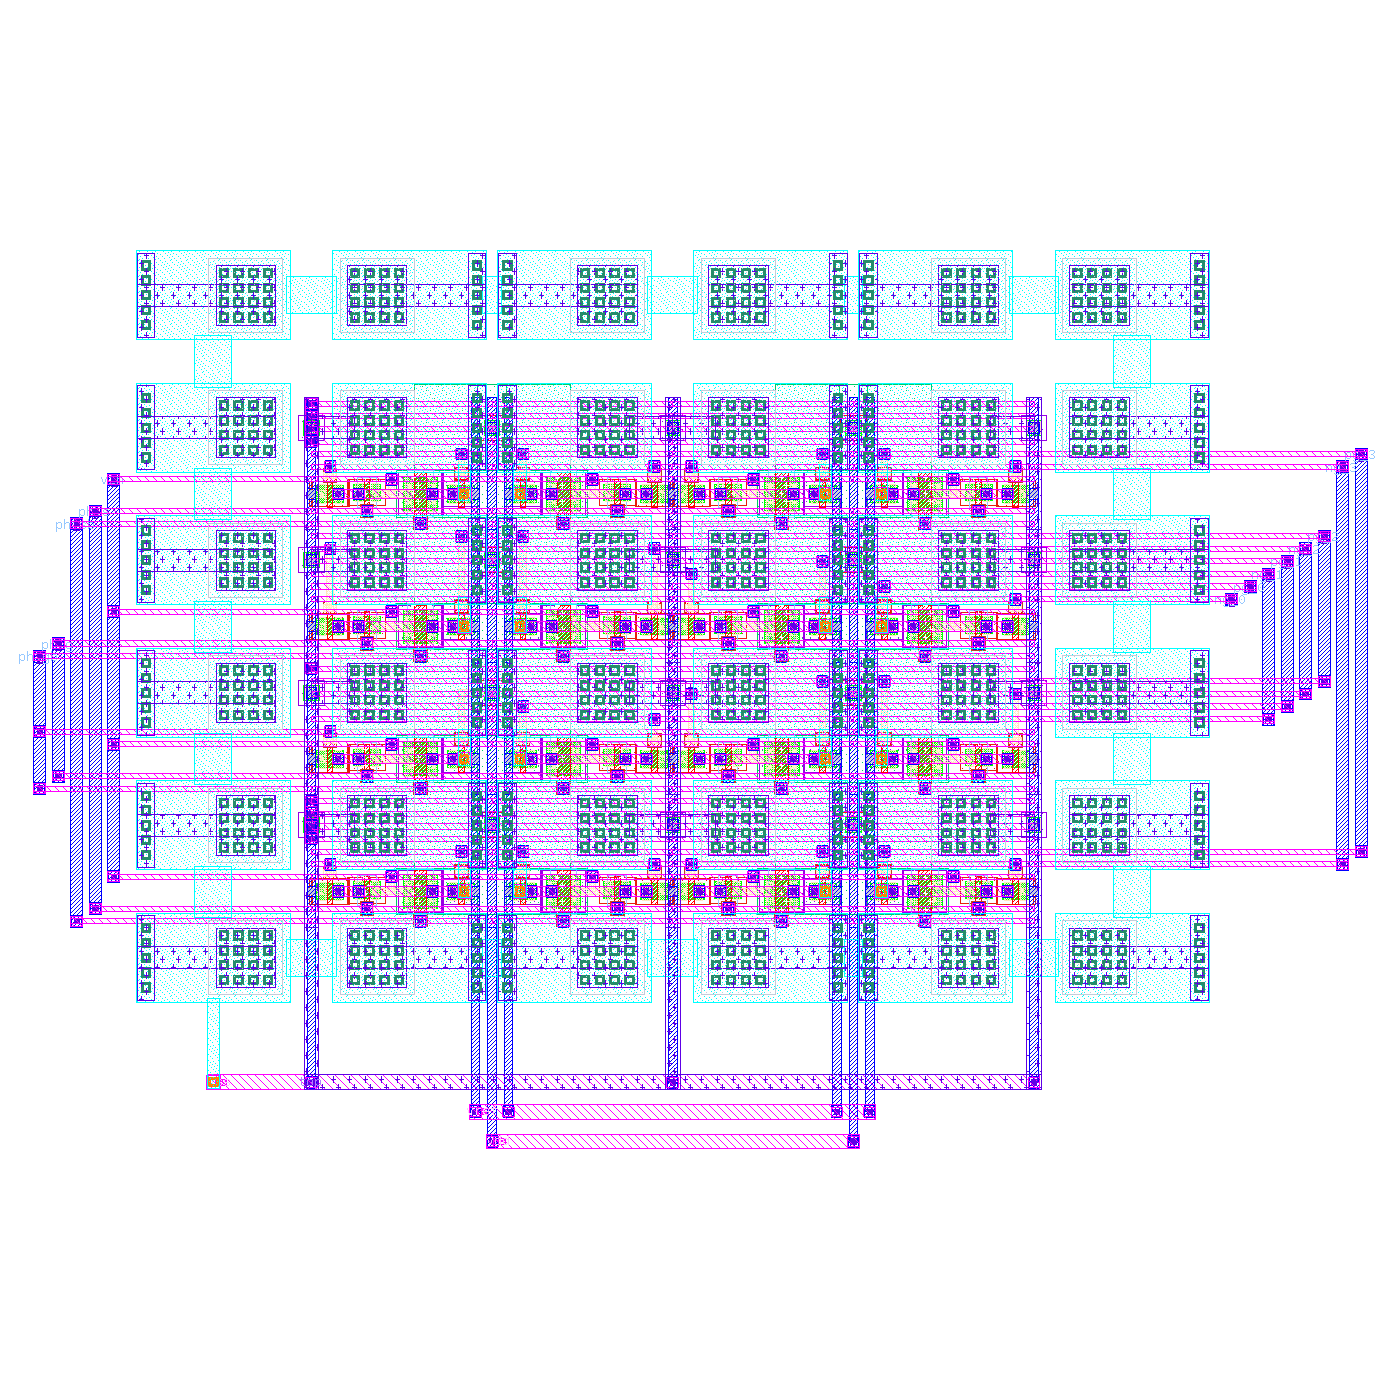

strongarm


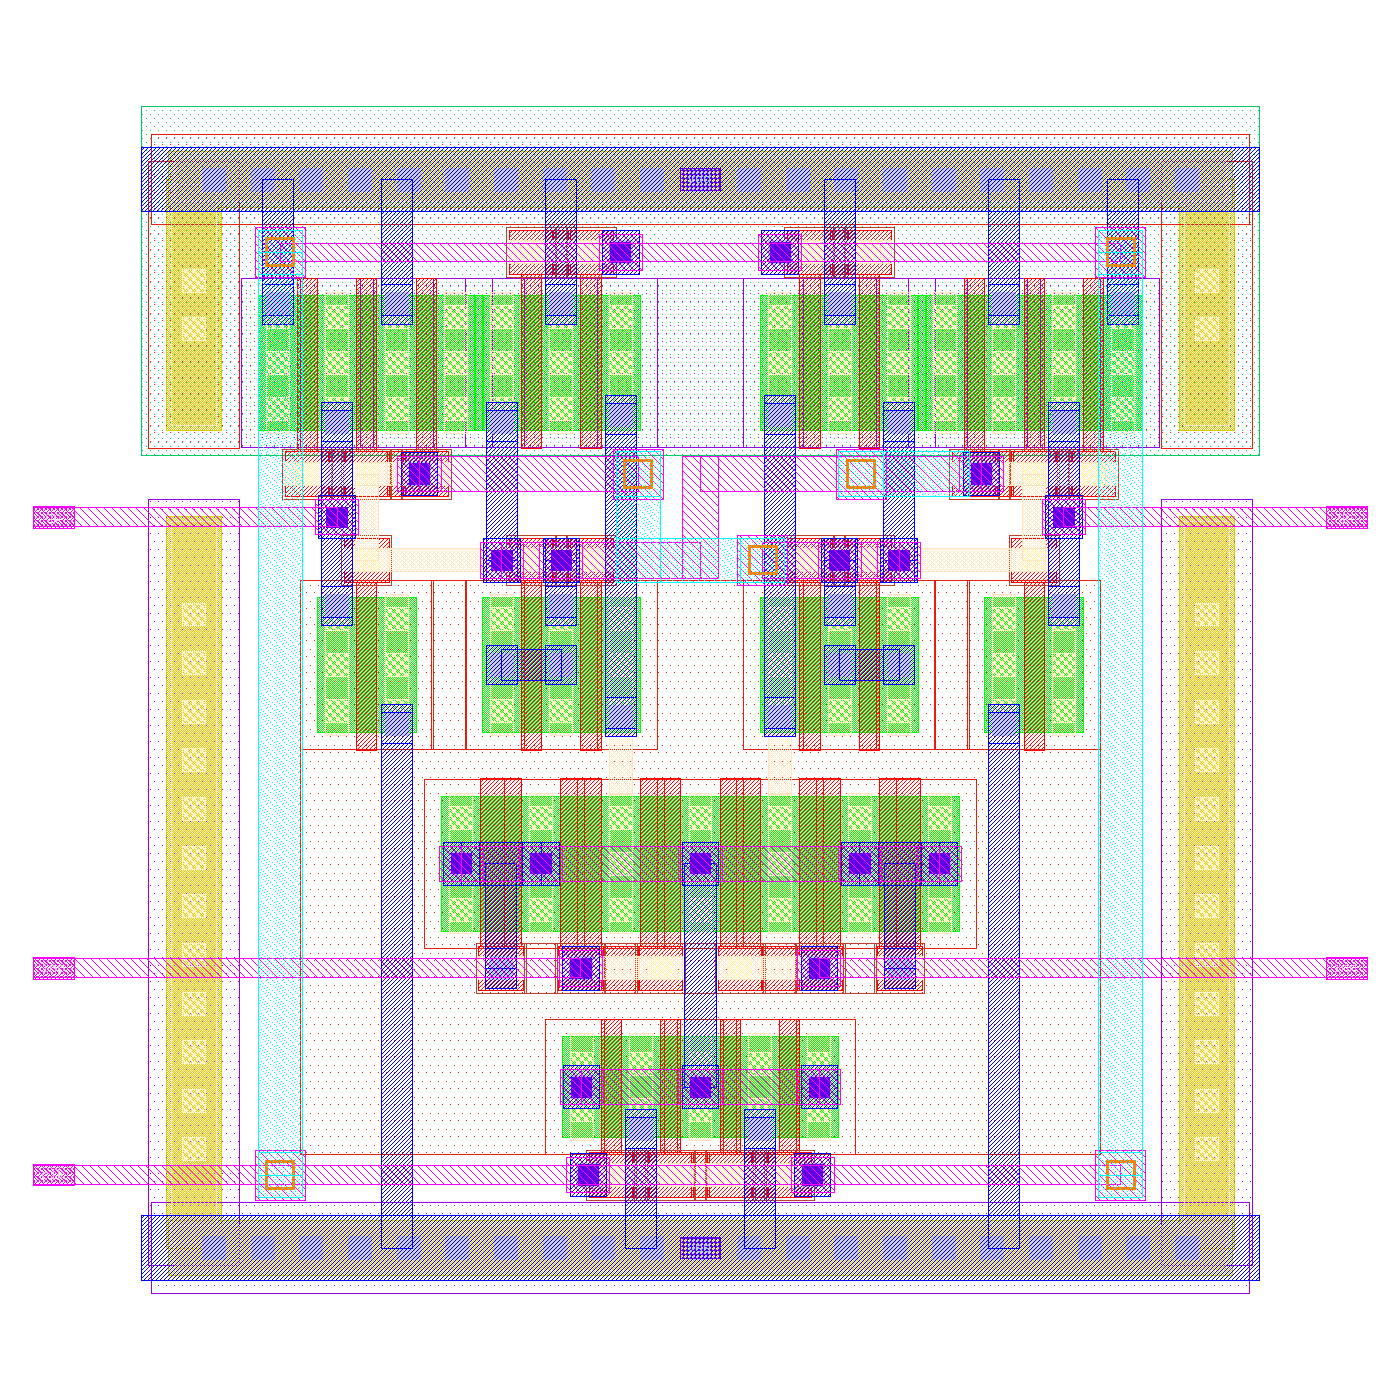

topsw


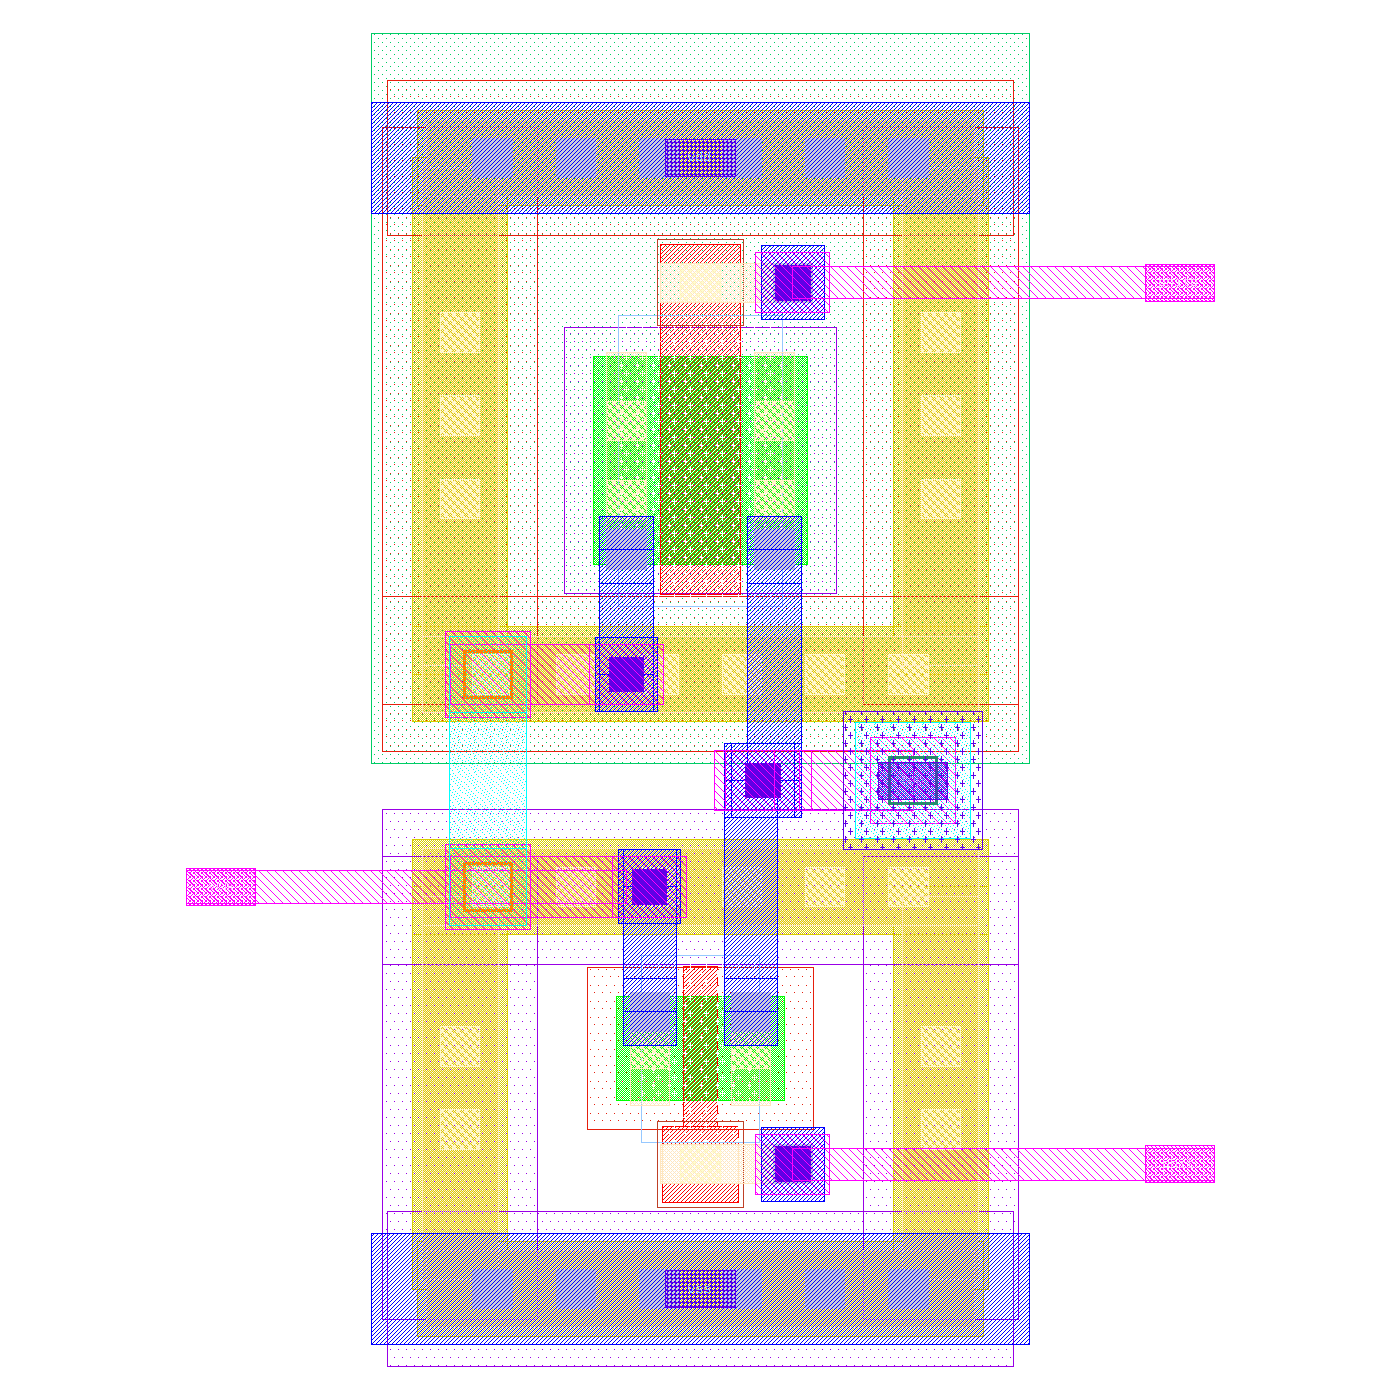

sar_logic


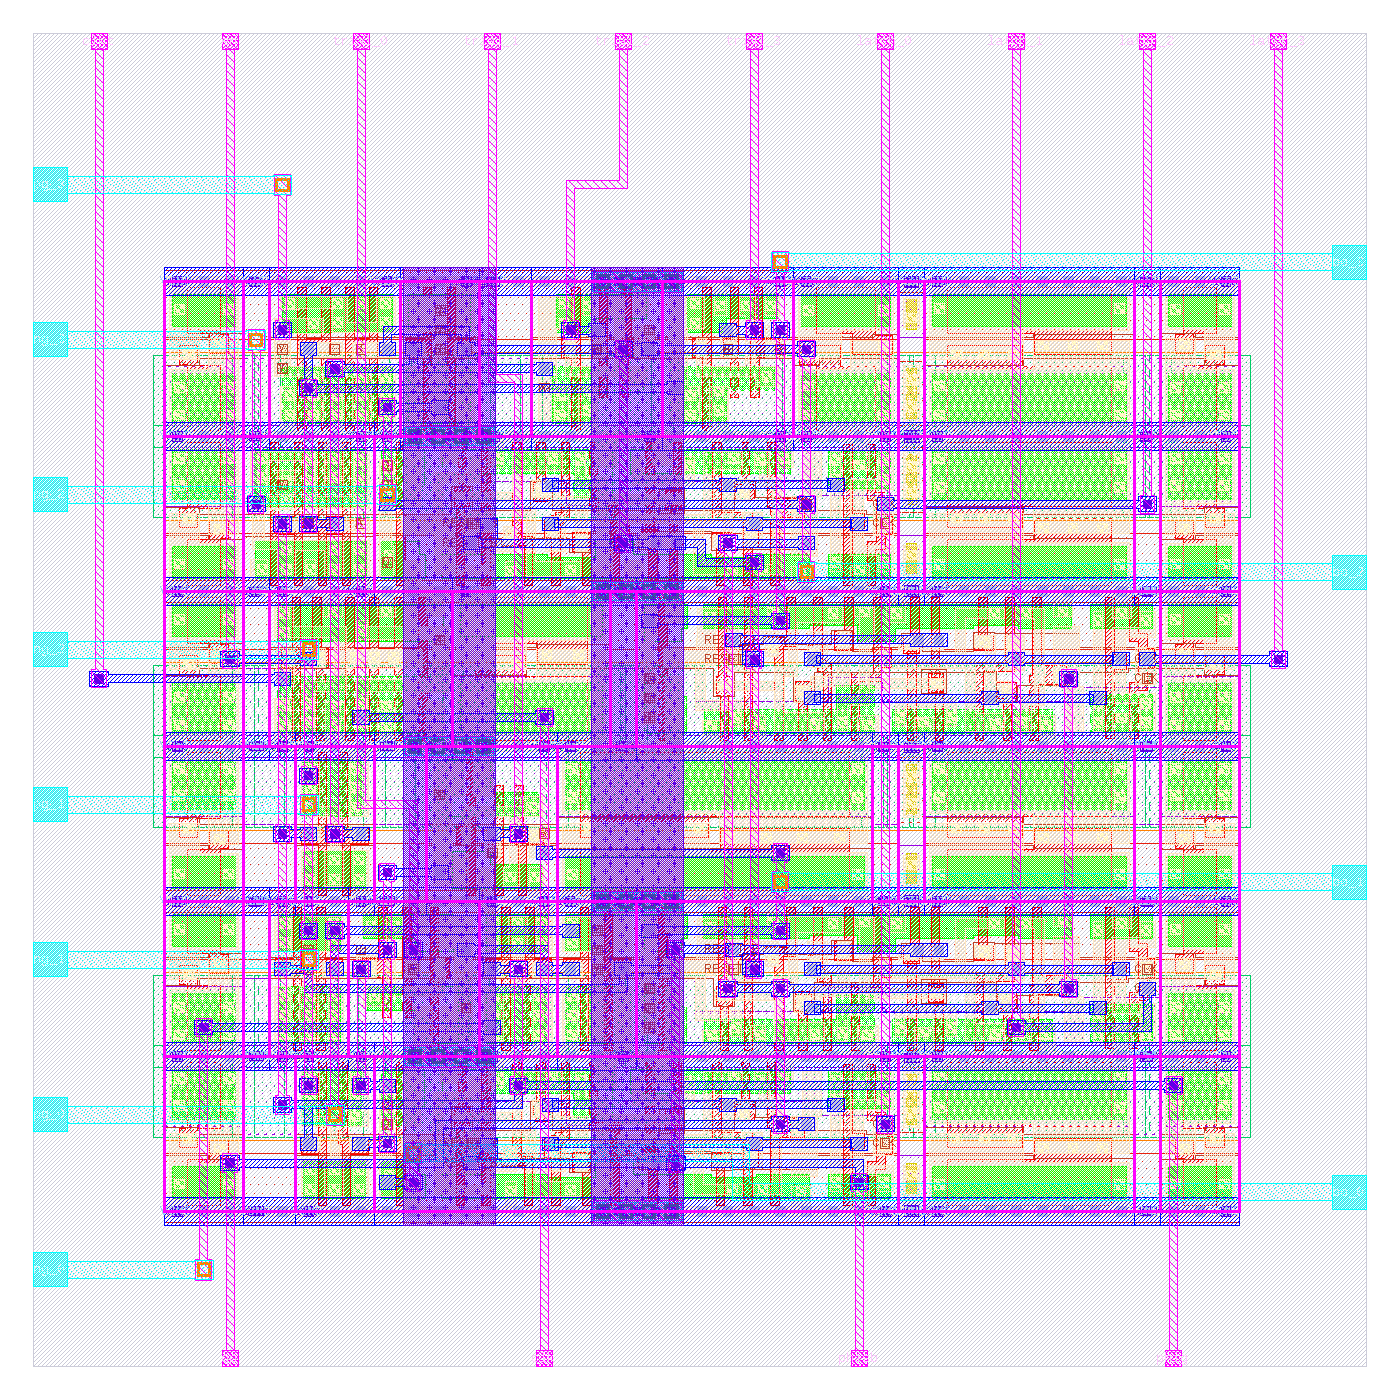

sar4b_core


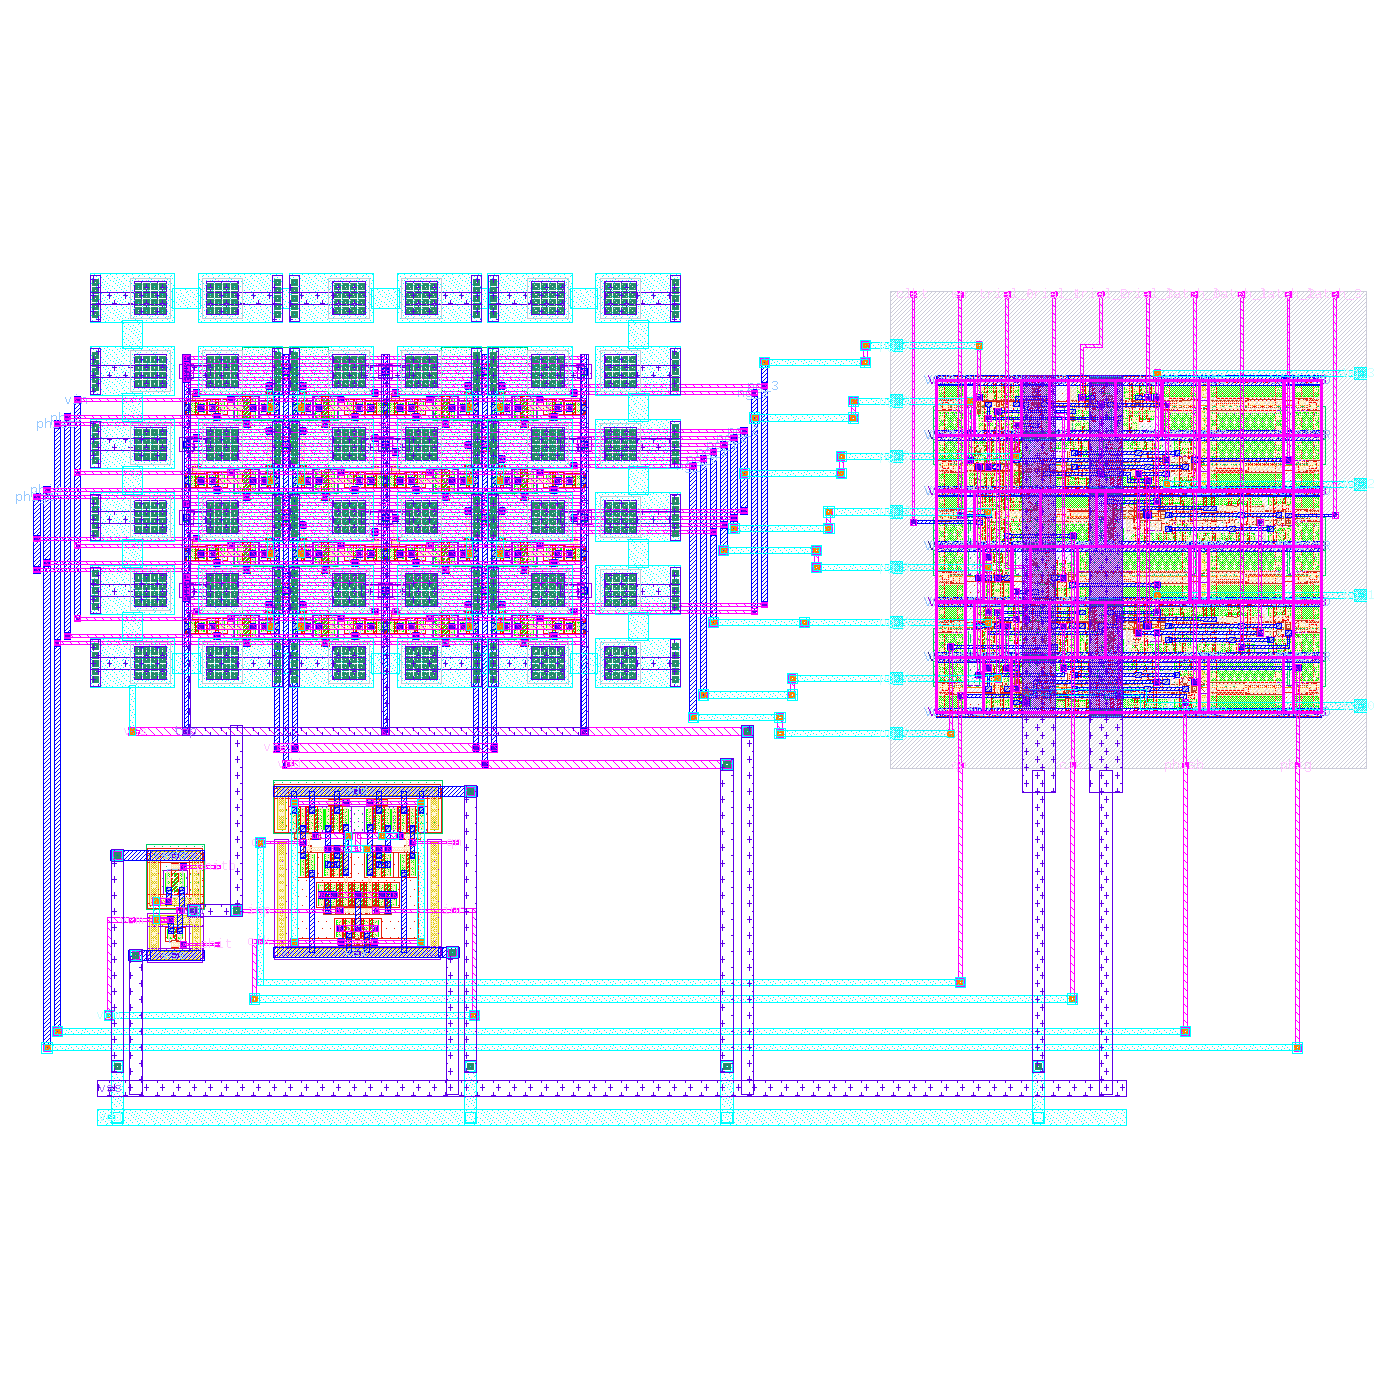

In [ ]:
L = R / "4bit/layout"
show(L / "signoff.md")
for name in ("cdac_unit", "cdacu4b", "strongarm", "topsw", "sar_logic", "sar4b_core"):
    print(name); show(L / f"{name}.png")

**Pre- vs. post-layout** - the same testbench with extracted blocks (Magic, parasitic capacitance) in place of the
schematic ones; "full core from layout" replaces CDAC, comparator, top-plate switch and SAR logic by the extraction
of the routed core.

In [ ]:
show(L / "prepost.md")

| metric | schematic | extracted CDAC | extracted comparator | extracted CDAC + comparator | extracted switches | all blocks extracted | compact CDAC+switches | compact CDAC+switches + comparator | unit-cell CDAC | unit-cell CDAC + comparator | full core from layout |
|---|---|---|---|---|---|---|---|---|---|---|---|
| ENOB [bit] | 3.957 | 3.981 | 3.987 | 3.978 | 3.972 | 3.997 | 3.906 | 3.933 | 3.952 | 3.976 | 3.976 |
| max DNL [LSB] | 0.063 | 0.104 | 0.037 | 0.029 | 0.070 | 0.037 | 0.137 | 0.070 | 0.004 | 0.037 | 0.037 |
| max INL [LSB] | 0.081 | 0.100 | 0.047 | 0.017 | 0.066 | 0.045 | 0.133 | 0.057 | 0.000 | 0.026 | 0.024 |
| offset [LSB] | -0.122 | -0.122 | -0.089 | -0.022 | -0.089 | 0.011 | -0.056 | 0.044 | -0.122 | -0.056 | -0.089 |
| gain error [LSB] | -0.021 | -0.055 | -0.021 | -0.021 | -0.055 | -0.021 | -0.287 | -0.254 | -0.055 | -0.088 | -0.021 |
| power [uW] | 13.929 | 14.677 | 15.209 | 22.477 | 17.022 | 25.572 | 19.901 | 27.691 | 17.393 | 19.165 | 25.379 |


**The extracted core across PVT** - the same corners as the schematic sweep of section 12, with the routed
core's extraction in place of every block (`studies/postlayout_pvt.py`). Linearity holds in the extracted
cores; power rises by ~80 %, mostly from the switch-control and clock wiring the logic drives and the CDAC's
bottom-plate parasitics (breakdown in `docs/layout_findings.md`, 6c).

| point | corner | temp | vdd | enob | sndr_db | sfdr_db | f_in | dnl_max | inl_max | missing | dnl_t | inl_t | offset_lsb | gain_lsb | p_uw |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| tt -40C 1.80V | tt | -40 | 1.8 | 3.97 | 25.7 | 36.7 | 1.02e+06 | 0 | 0 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 24.7 |
| tt +27C 1.80V | tt | 27 | 1.8 | 3.98 | 25.7 | 37.4 | 1.02e+06 | 0 | 0 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 25.4 |
| tt +125C 1.80V | tt | 125 | 1.8 | 3.98 | 25.7 | 35.9 | 1.02e+06 | 0 | 0 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 27.7 |
| ss -40C 1.80V | ss | -40 | 1.8 | 4.01 | 25.9 | 34.3 | 1.02e+06 | 0 | 0 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 24.9 |
| ss +27C 1.80V | ss | 27 | 1.8 | 3.96 | 25.6 | 36.4 | 1.02e+06 | 0 | 0 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 25.4 |
| ss +125C 1.80V | ss | 125 | 1.8 | 3.95 | 25.5 | 36.6 | 1.02e+06 | 0.123 | 0.0943 | 0 | 0.129 | 0.0949 | -0.139 | 0.0781 | 26.5 |
| ff -40C 1.80V | ff | -40 | 1.8 | 3.99 | 25.8 | 36.2 | 1.02e+06 | 0 | 0 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 24.7 |
| ff +27C 1.80V | ff | 27 | 1.8 | 3.97 | 25.7 | 34.6 | 1.02e+06 | 0 | 0 | 0 | 0.00391 | 1.15e-15 | -0.0723 | -0.0547 | 25.9 |
| ff +125C 1.80V | ff | 125 | 1.8 | 3.97 | 25.6 | 34.8 | 1.02e+06 | 0.0711 | 0.0616 | 0 | 0.0703 | 0.0617 | -0.139 | 0.0117 | 35.6 |
| sf -40C 1.80V | sf | -40 | 1.8 | 3.96 | 25.6 | 34 | 1.02e+06 | 0.0667 | 0.0667 | 0 | 0.0703 | 0.0664 | -0.139 | -0.0547 | 24.8 |
| sf +27C 1.80V | sf | 27 | 1.8 | 3.96 | 25.6 | 34 | 1.02e+06 | 0 | 0 | 0 | 0.00391 | 1.3e-15 | -0.139 | -0.0547 | 25.4 |
| sf +125C 1.80V | sf | 125 | 1.8 | 3.96 | 25.6 | 34 | 1.02e+06 | 0 | 0 | 0 | 0.00391 | 1.3e-15 | -0.139 | -0.0547 | 26.6 |
| fs -40C 1.80V | fs | -40 | 1.8 | 3.98 | 25.7 | 37.7 | 1.02e+06 | 0.0622 | 0.0574 | 0 | 0.0703 | 0.0569 | -0.00586 | -0.121 | 25 |
| fs +27C 1.80V | fs | 27 | 1.8 | 3.98 | 25.7 | 37.3 | 1.02e+06 | 0.0667 | 0.0667 | 0 | 0.0703 | 0.0664 | -0.00586 | -0.0547 | 27.7 |
| fs +125C 1.80V | fs | 125 | 1.8 | 3.98 | 25.7 | 36.5 | 1.02e+06 | 0.123 | 0.123 | 0 | 0.129 | 0.123 | -0.205 | 0.0781 | 45 |
| tt +27C 1.62V | tt | 27 | 1.62 | 3.97 | 25.6 | 36.2 | 1.02e+06 | 0.0667 | 0.0667 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 20.4 |
| tt +27C 1.98V | tt | 27 | 1.98 | 3.98 | 25.7 | 35.6 | 1.02e+06 | 0.0667 | 0.0667 | 0 | 0.0703 | 0.0664 | -0.0723 | -0.0547 | 31.1 |


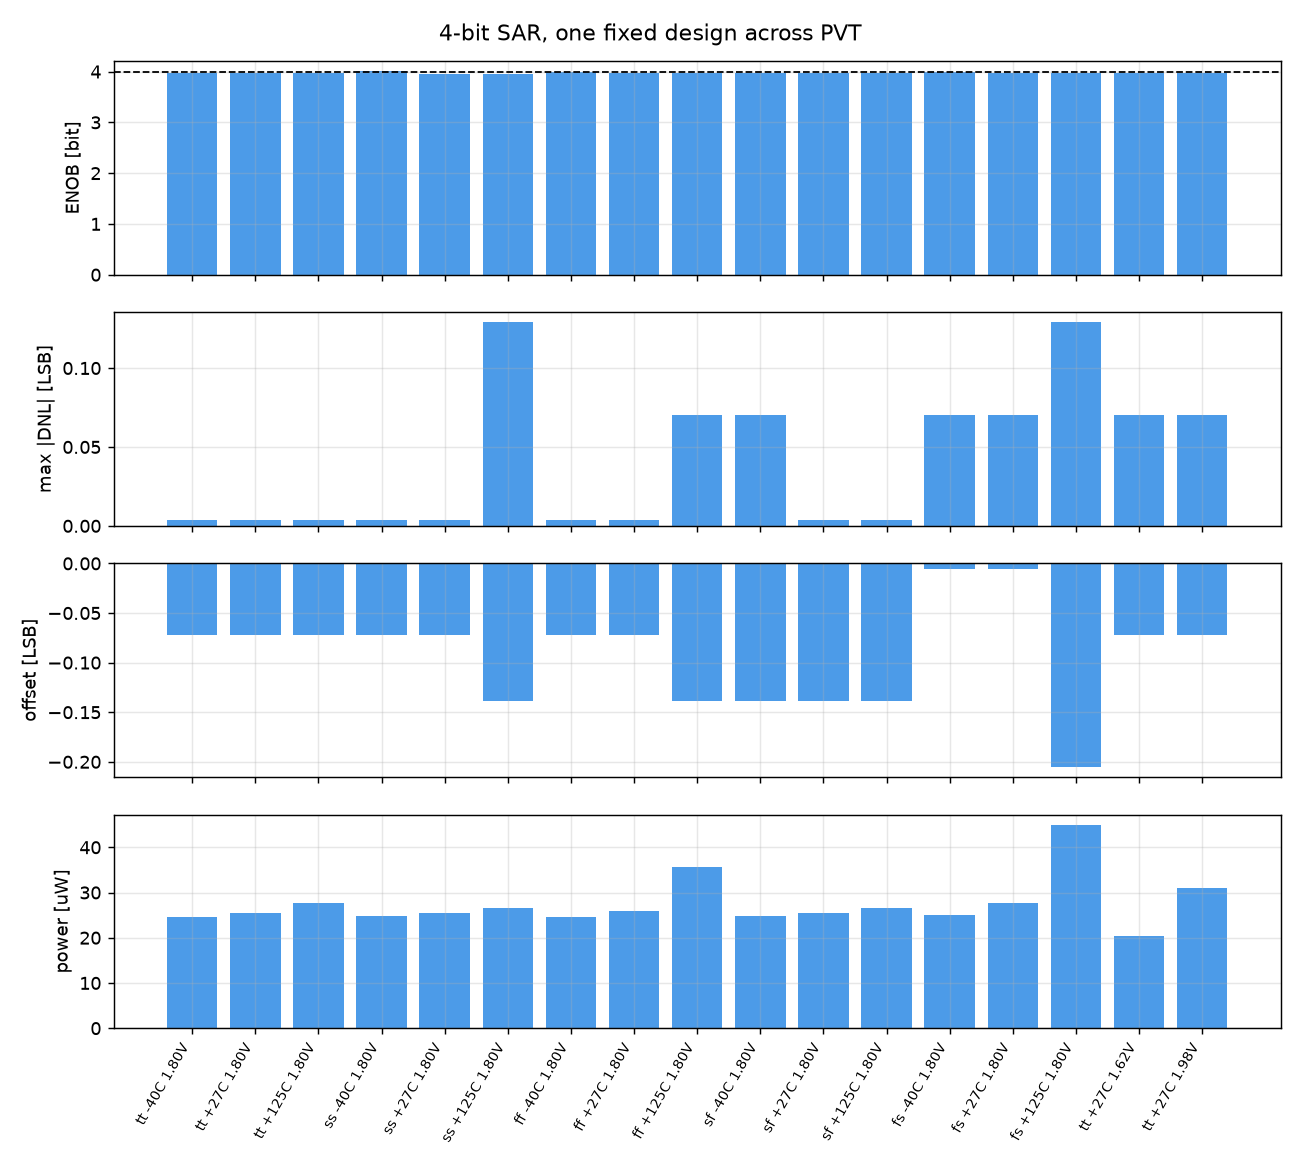

In [ ]:
show(L / "pvt_core.md"); show(L / "pvt_core.png")

**The same generators at 6 bit** - 64 unit capacitors instead of 16 in the same common-centroid packing and dummy ring, a larger top-plate
switch and SAR logic; nothing was redrawn by hand.

| block | size [um] | area [um^2] | KLayout DRC (incl. capm.10) | magic DRC | LVS |
|---|---|---|---|---|---|
| 6-bit CDAC (common-centroid, dummy-cap ring) | 57.54 x 38.58 | 2220 | 0 | 0 | match (321/321 devices) |
| StrongARM comparator | 11.43 x 8.99 | 103 | 0 | 0 | match (18/18 devices) |
| top-plate sampling switch (guard rings) | 6.37 x 7.52 | 48 | 0 | 0 | match (2/2 devices) |
| SAR logic (LibreLane, sky130_fd_sc_hd) | 28.30 x 28.30 | 801 | 0 | 0 | match (30/30 devices) |
| 6-bit SAR ADC core (all blocks routed) | 94.24 x 57.34 | 5404 | 0 | 0 | match (4/4 block instances) |


cdacu6b


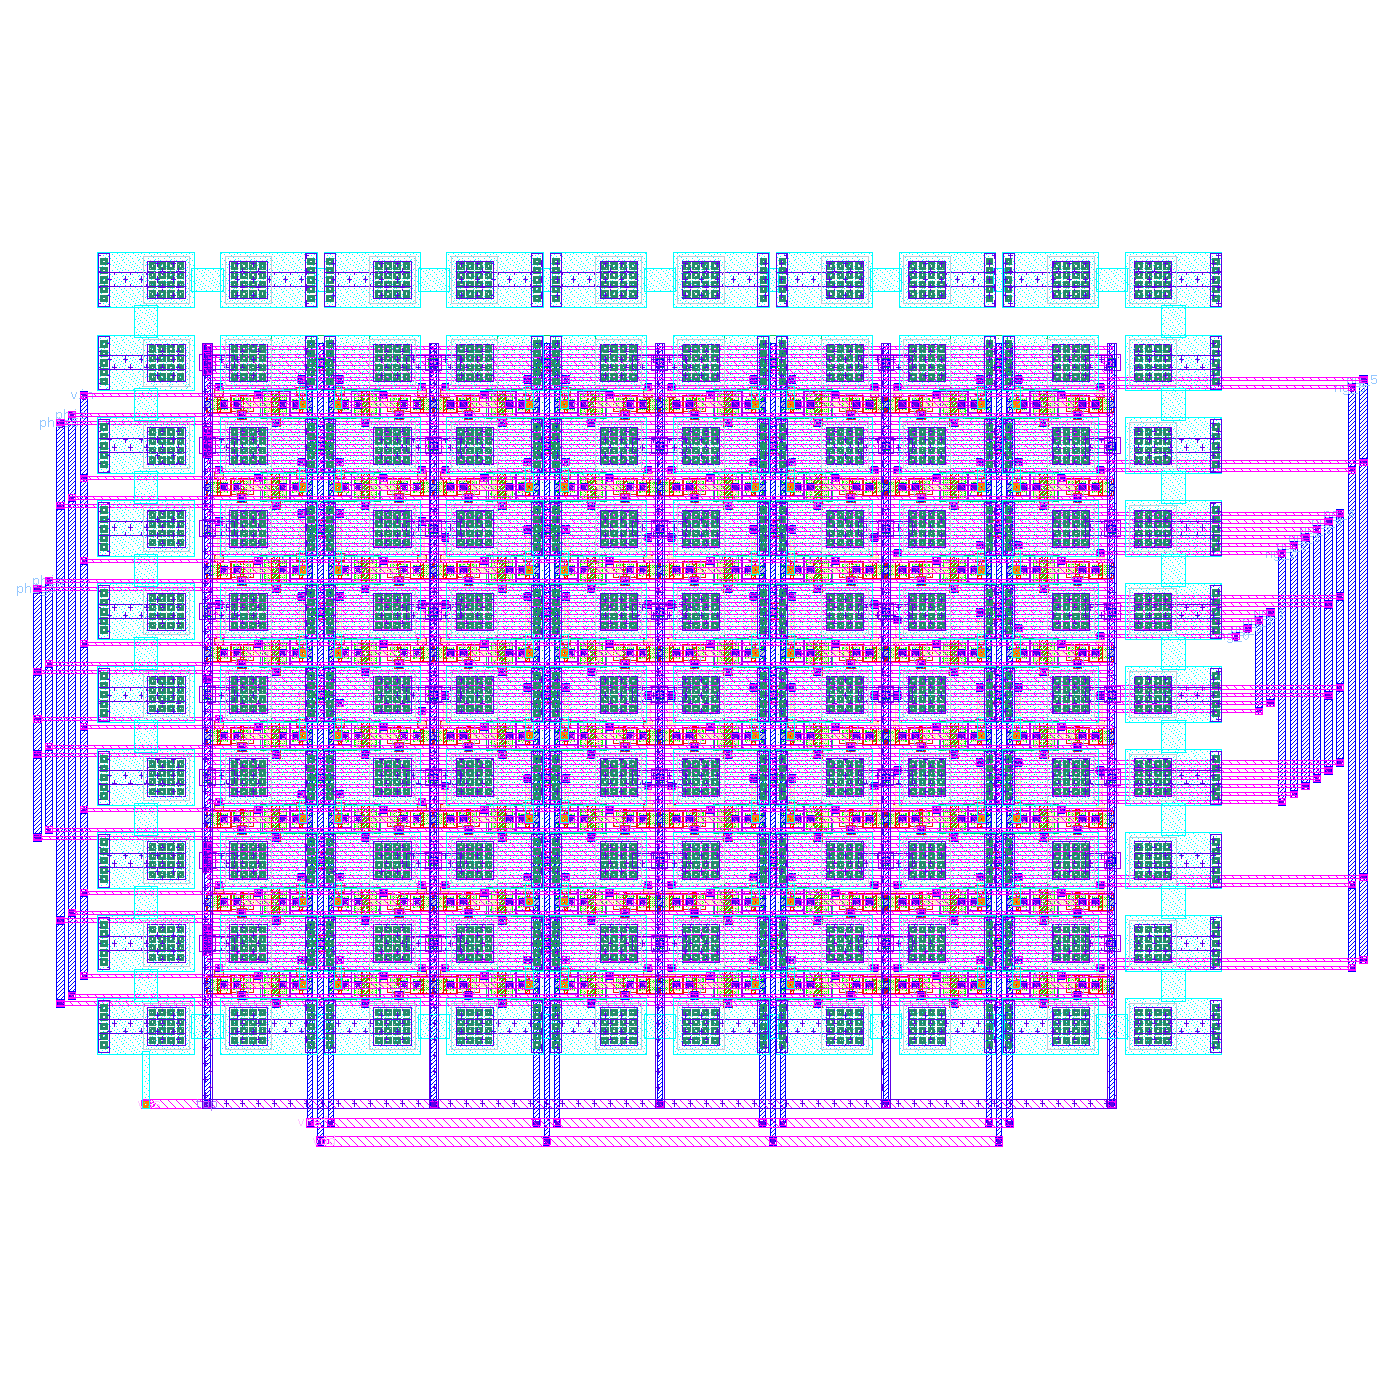

sar6b_core


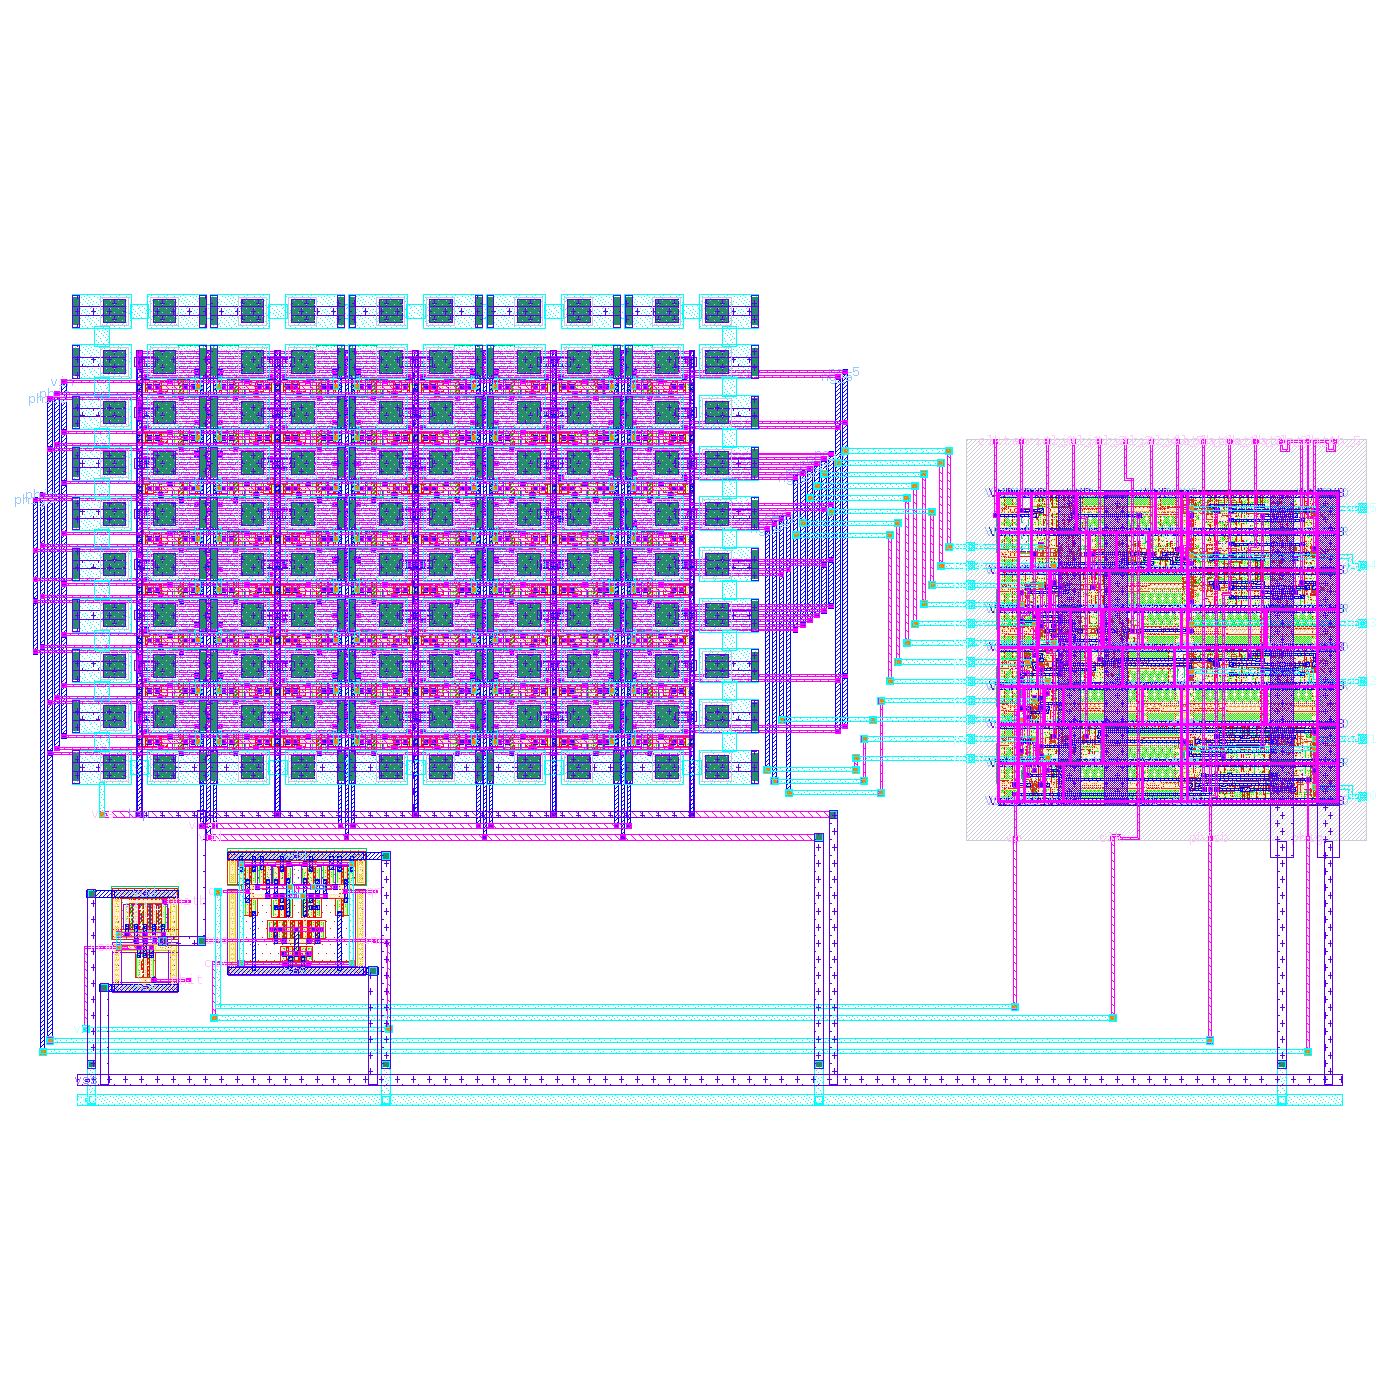

| metric | schematic | full core from layout |
|---|---|---|
| ENOB [bit] | 6.010 | 6.024 |
| max DNL [LSB] | 0.207 | 0.048 |
| max INL [LSB] | 0.165 | 0.067 |
| offset [LSB] | -0.119 | -0.183 |
| gain error [LSB] | 0.017 | -0.110 |
| power [uW] | 33.821 | 63.088 |


In [ ]:
L6 = R / "6bit/layout"
show(L6 / "signoff.md")
for name in ("cdacu6b", "sar6b_core"):
    print(name); show(L6 / f"{name}.png")
show(L6 / "prepost.md")

**The same generators at 8 bit** - 256 unit capacitors in the same packing and dummy ring, the comparator with a
14-finger input pair, 28-finger tail and 9-finger latch, a 17 + 34-finger top-plate switch and the 8-bit SAR logic,
routed into one core. At 8 bit the sizing makes the unit cap matching-limited (2.7 x 2.7 um instead of the 2 um minimum),
and the layout uses the sized cap, so schematic and layout compare the same array. The extracted 8-bit core takes
~2.7 h per transient run, so post-layout uses 4 ramp hits per code: DNL is resolved in 1/4-LSB steps, while ENOB
(coherent FFT) is unaffected. The top-plate wiring adds ~330 fF, but its coupling to the bottom plates is the same
1.00 fF on every unit cap, so it scales all bit weights alike.

| block | size [um] | area [um^2] | KLayout DRC (incl. capm.10) | magic DRC | LVS |
|---|---|---|---|---|---|
| CDAC unit cell (MIM cap + its own switches) | 6.35 x 5.67 | 36 | 0 | 0 | match (5/5 devices) |
| unit-cell abutment test (2 x 3) | 18.17 x 13.16 | 239 | 0 | 0 | match (30/30 devices) |
| 8-bit CDAC (common-centroid, dummy-cap ring) | 112.08 x 79.45 | 8905 | 0 | 0 | match (1281/1281 devices) |
| StrongARM comparator | 32.63 x 12.47 | 407 | 0 | 0 | match (18/18 devices) |
| top-plate sampling switch (guard rings) | 25.57 x 8.42 | 215 | 0 | 0 | match (2/2 devices) |
| SAR logic (LibreLane, sky130_fd_sc_hd) | 33.50 x 33.50 | 1122 | 0 | 0 | match (38/38 devices) |
| 8-bit SAR ADC core (all blocks routed) | 156.38 x 101.17 | 15821 | 0 | 0 | match (4/4 block instances) |


cdacu8b


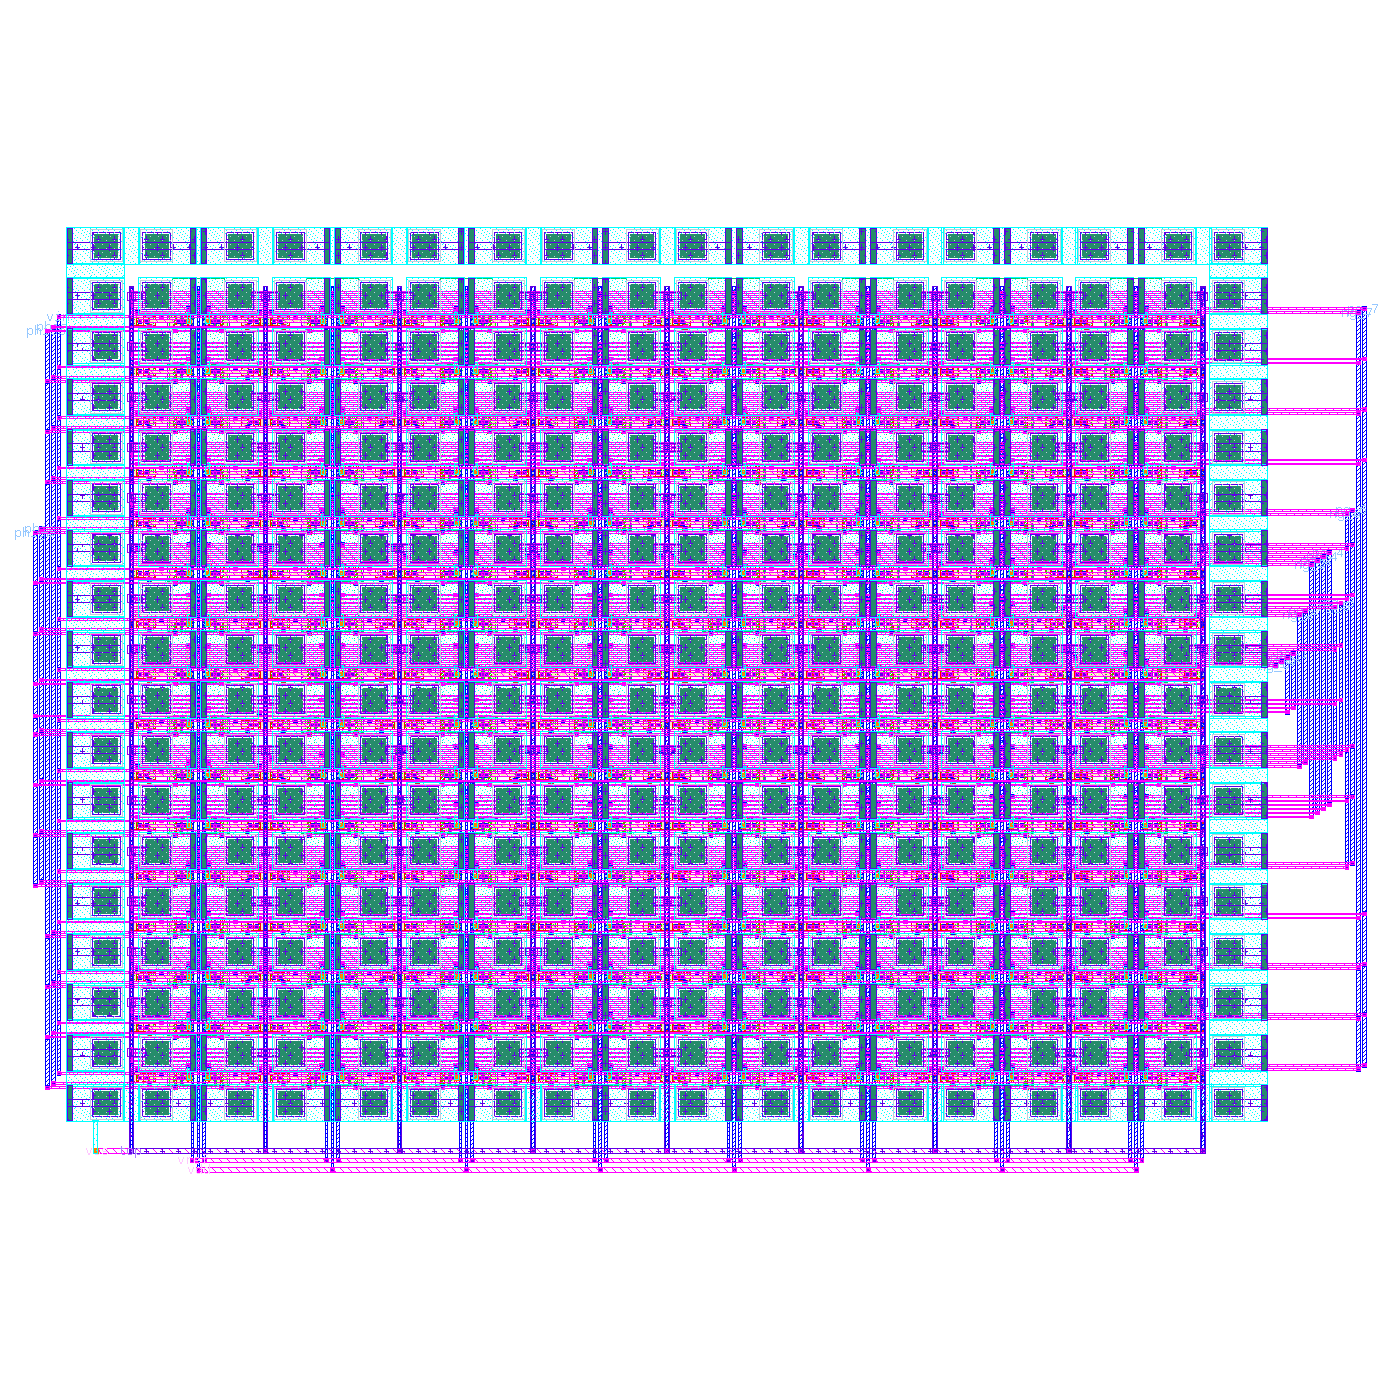

strongarm


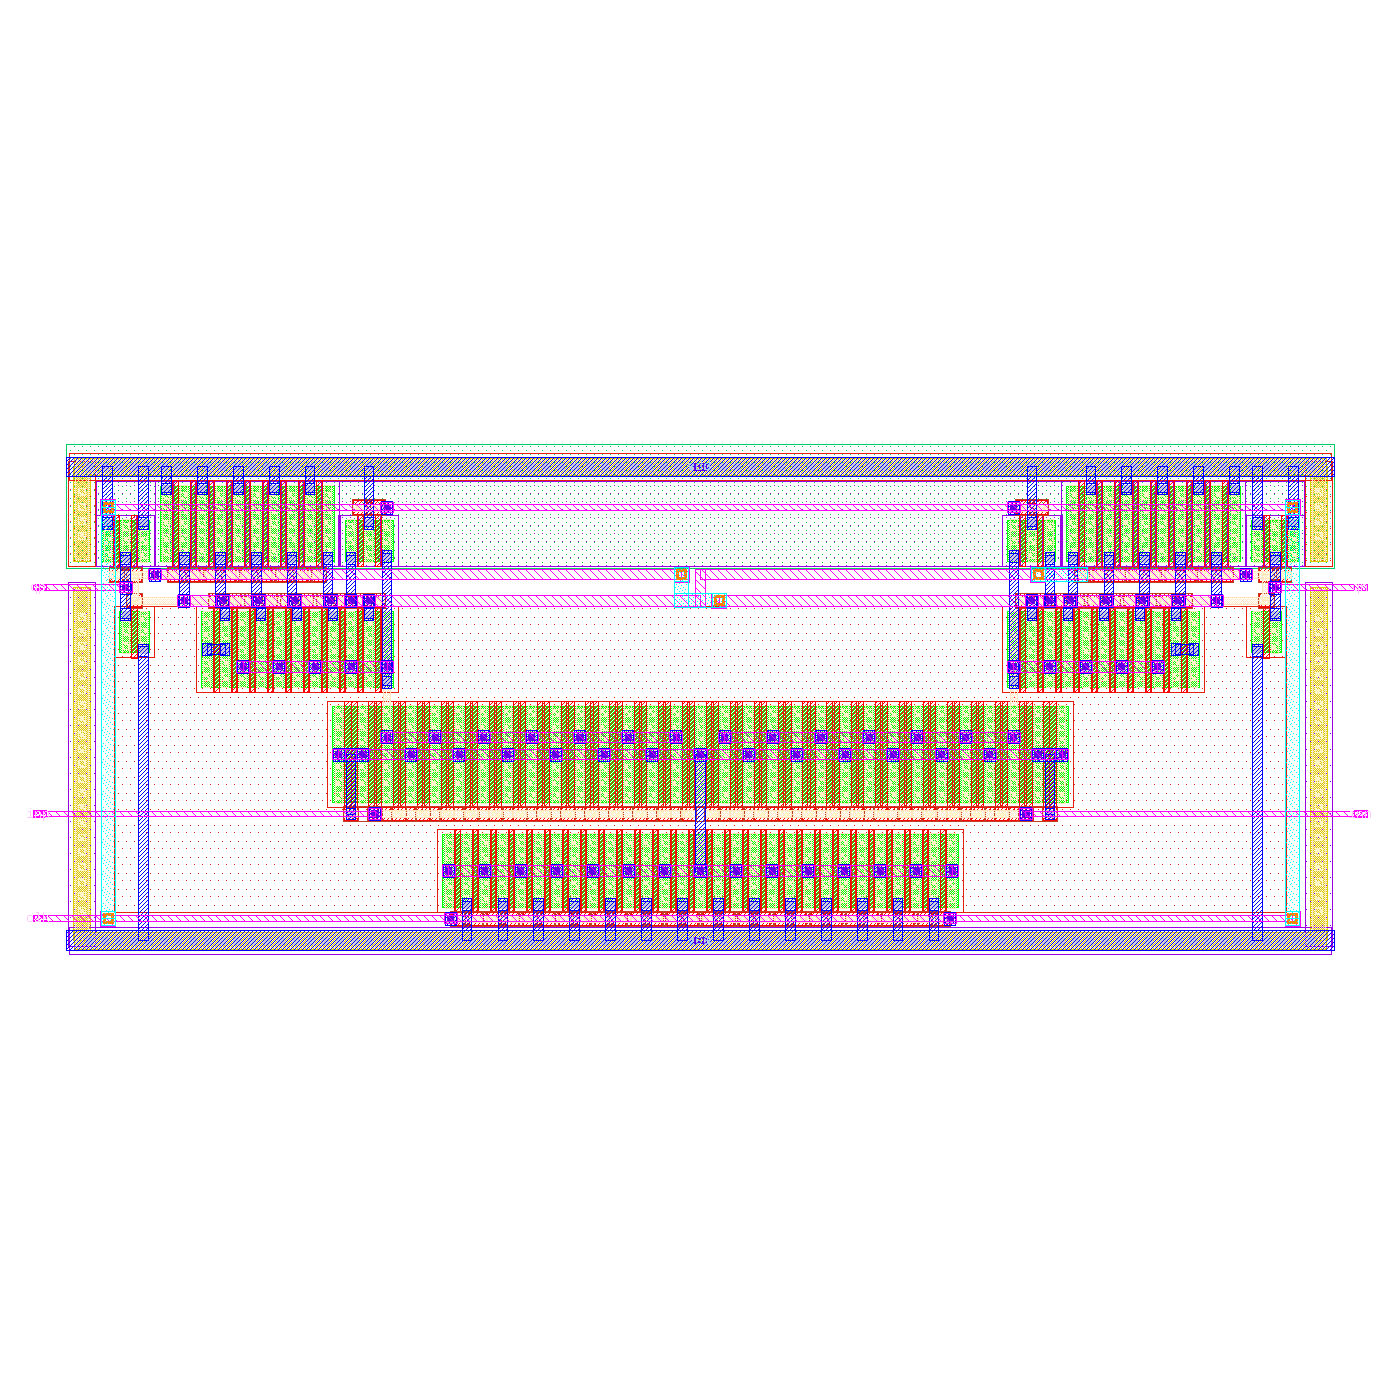

topsw


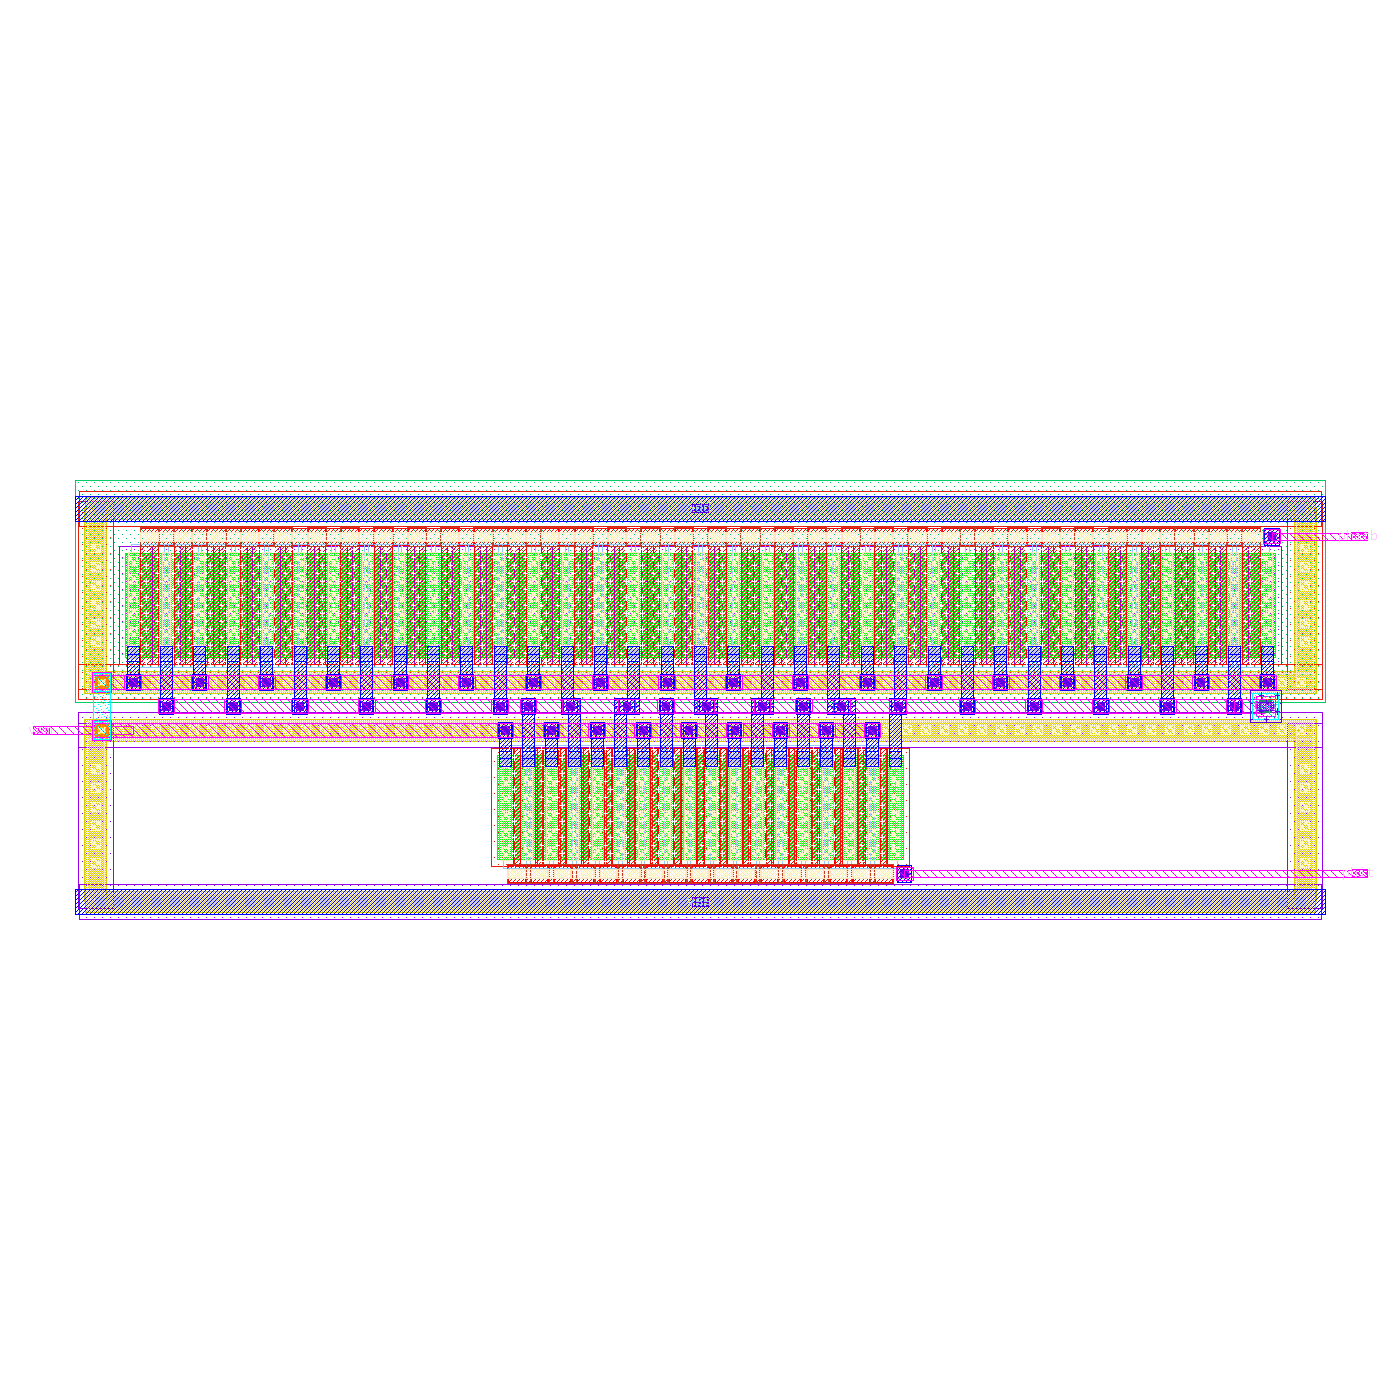

sar8b_core


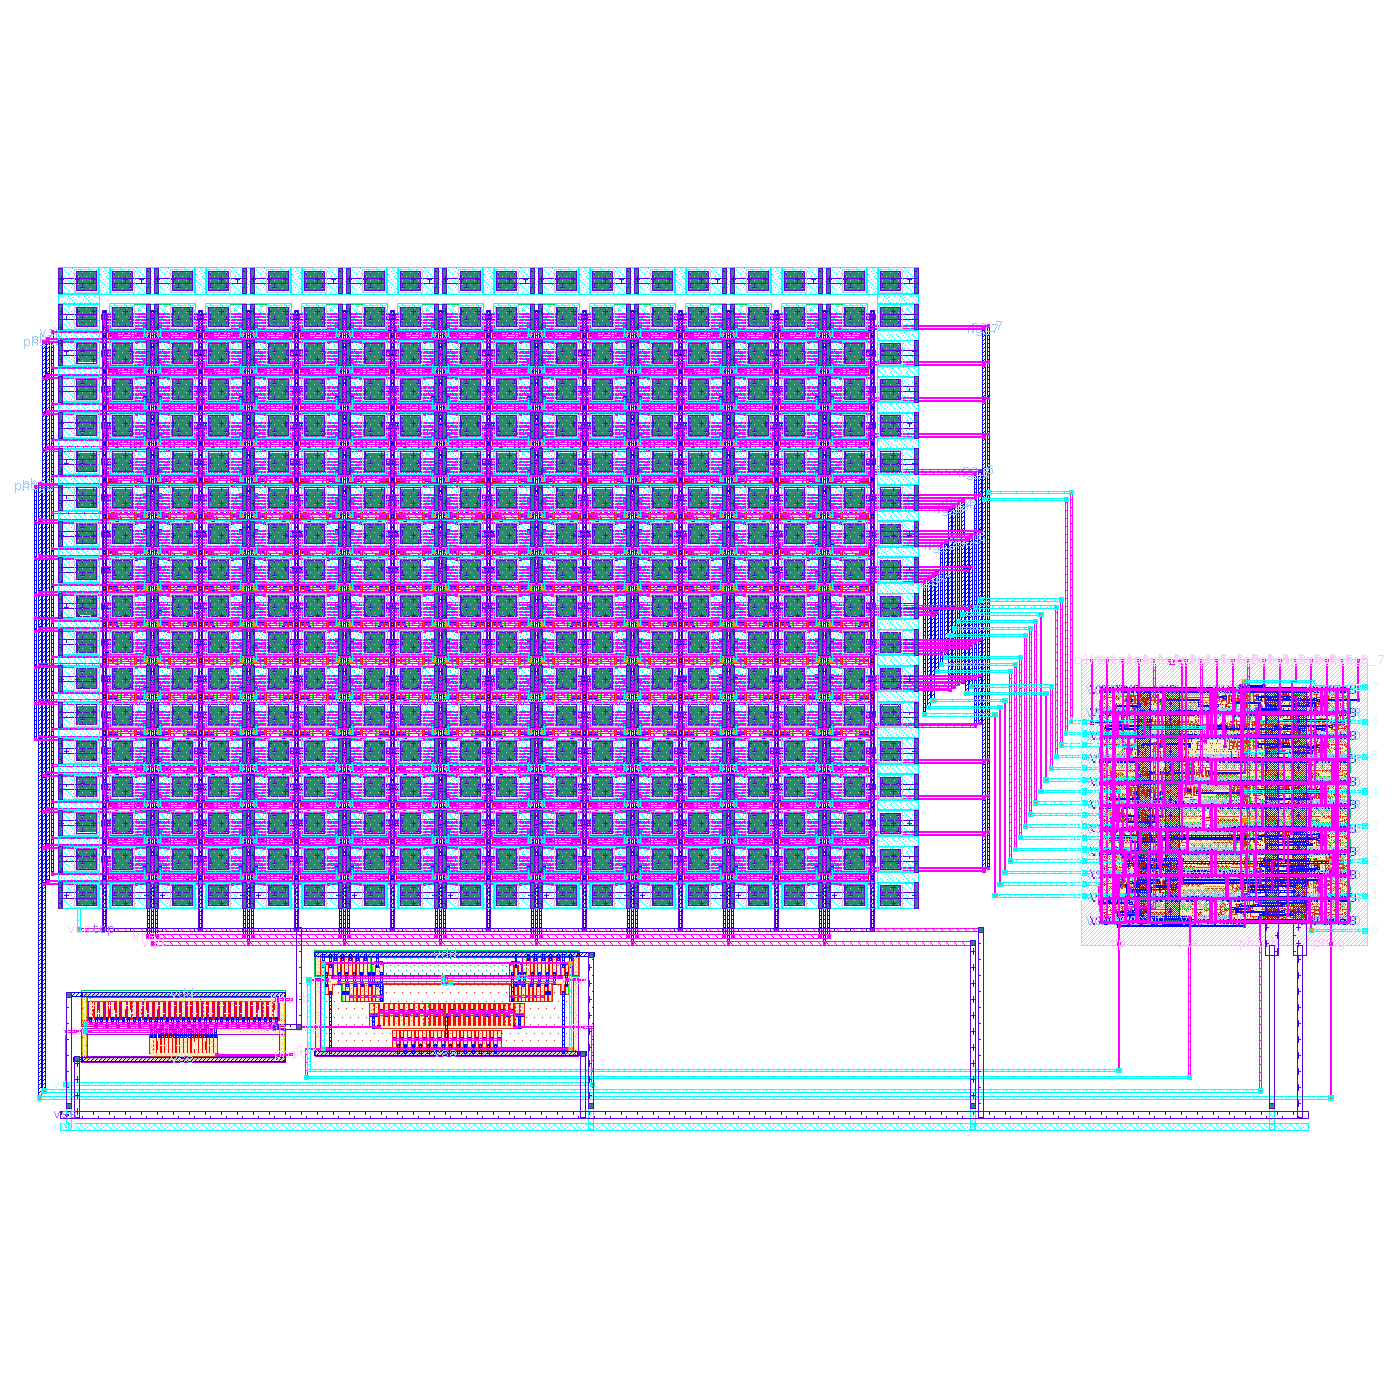

| metric | schematic | full core from layout |
|---|---|---|
| ENOB [bit] | 7.979 | 7.984 |
| max DNL [LSB] | 0.255 | 0.255 |
| max INL [LSB] | 0.277 | 0.288 |
| offset [LSB] | -0.873 | -0.622 |
| gain error [LSB] | -0.514 | -0.765 |
| power [uW] | 186.643 | 277.653 |


In [ ]:
L8 = R / "8bit/layout"
show(L8 / "signoff.md")
for name in ("cdacu8b", "strongarm", "topsw", "sar8b_core"):
    print(name); show(L8 / f"{name}.png")
show(L8 / "prepost.md")

**Top-plate switch threshold vs. PVT** (schematic, fixed 4-bit design; `studies/top_switch_leakage.py`). The floating
top plate leaks through the switch's PMOS when hot (LVT), but the same PMOS carries the settling when cold
(standard-Vt): no threshold choice wins every corner at this size. Decision: keep the sized LVT gate - the extracted
4-bit core stays within DNL 0.13 LSB at every corner (table above). A later revision can size the PMOS for both ends
(wider standard-Vt or longer-L LVT) or bootstrap it.

In [ ]:
show(R / "4bit/sweeps/top_switch_leakage.md")

| top-plate switch | corner | ENOB | DNL [LSB] | INL [LSB] | offset [LSB] | gain [LSB] | power [uW] |
|---|---|---|---|---|---|---|---|
| LVT N + LVT P (sized) | ff +125C 1.80V | 3.96 | 0.195 | 0.185 | -0.27 | +0.14 | 23.5 |
| LVT N + LVT P (sized) | fs +125C 1.80V | 3.95 | 0.262 | 0.285 | -0.40 | +0.28 | 31.1 |
| LVT N + LVT P (sized) | ss -40C 1.80V | 3.98 | 0.063 | 0.057 | -0.07 | +0.01 | 13.6 |
| LVT N + LVT P (sized) | tt +27C 1.80V | 3.96 | 0.129 | 0.100 | -0.14 | +0.01 | 13.9 |
| SVT N + SVT P | ff +125C 1.80V | 3.97 | 0.070 | 0.057 | -0.14 | +0.01 | 23.2 |
| SVT N + SVT P | fs +125C 1.80V | 3.98 | 0.070 | 0.062 | -0.14 | +0.01 | 30.9 |
| SVT N + SVT P | sf -40C 1.80V | 3.98 | 0.004 | 0.000 | -0.07 | -0.05 | 13.4 |
| SVT N + SVT P | ss -40C 1.62V | 2.99 | 0.203 | - | +1.79 | +nan | 10.8 |
| SVT N + SVT P | ss -40C 1.80V | 3.19 | 0.203 | 0.180 | +0.99 | -0.12 | 13.6 |
| SVT N + SVT P | tt +27C 1.80V | 3.94 | 0.129 | 0.066 | -0.07 | -0.05 | 13.9 |
| SVT N + LVT P | ff +125C 1.80V | 3.96 | 0.195 | 0.185 | -0.27 | +0.14 | 23.4 |
| SVT N + LVT P | fs +125C 1.80V | 3.94 | 0.328 | 0.332 | -0.47 | +0.41 | 31.0 |
| SVT N + LVT P | sf -40C 1.80V | 3.97 | 0.004 | 0.000 | -0.07 | -0.05 | 13.4 |
| SVT N + LVT P | ss -40C 1.62V | 3.74 | 0.129 | 0.100 | -0.07 | +0.01 | 10.9 |
| SVT N + LVT P | ss -40C 1.80V | 3.99 | 0.070 | 0.066 | -0.07 | -0.05 | 13.6 |
| SVT N + LVT P | tt +27C 1.80V | 3.98 | 0.129 | 0.076 | -0.14 | +0.08 | 13.9 |
| LVT N + SVT P | ff +125C 1.80V | 3.98 | 0.070 | 0.057 | -0.14 | +0.01 | 23.4 |
| LVT N + SVT P | fs +125C 1.80V | 3.98 | 0.070 | 0.066 | -0.07 | -0.05 | 30.9 |
| LVT N + SVT P | ss -40C 1.62V | 3.29 | 0.527 | 0.474 | +0.13 | +0.34 | 10.7 |
| LVT N + SVT P | ss -40C 1.80V | 3.60 | 0.070 | 0.066 | -0.07 | -0.05 | 13.5 |


**Checks beyond the ideal testbench** (studies inspired by the design literature; scripts in `studies/`).

* *Comparator noise* - ngspice has no device noise in transient analysis, so the input pair's thermal noise is
  injected as an equivalent `TRNOISE` source (its scaling checked against an RC filter) and the comparator itself
  integrates it; the input-referred sigma is read with the probability method (Razavi, SSC Magazine 2020): the input
  at which 16 % of the decisions flip.
* *Offset Monte Carlo of the extracted comparator* - PDK mismatch on every extracted finger.
* *Kickback* onto the floating top plate - the single-ended converter's comparator sees the CDAC on one input and
  V<sub>cm</sub> on the other; the plate floats for a whole conversion.
* *Real sources* - every source behind a TinyTapeout analog pin (500 Ohm, 5 pF), with on-chip decap on V<sub>ref</sub>
  and V<sub>cm</sub>.
* *Wiring resistance* (Magic extresist): comparator offset moves by 0.01 LSB and its delay by < 2 %; the CDAC's shared
  vref / vin trunks are <= 65 / 148 Ohm (tau ~ 0.6 ns against 8.5 ns of tracking), so capacitance-only extraction holds.

In [ ]:
for f in ("comparator_noise.md", "comparator_mc_layout.md", "comparator_kickback.md", "4bit/sweeps/source_impedance.md"):
    print(f); show(R / f)

comparator_noise.md


| bits | W/L input pair [um] | gm [mS] | T_int [ps] | sigma, estimate [uV] | sigma, simulated [uV] | LSB [mV] | sigma / LSB | SNR loss [dB] |
|---|---|---|---|---|---|---|---|---|
| 4 | 2.0/0.30 | 0.32 | 183 | 529 | 480 | 112.50 | 1/234 | 0.001 |
| 6 | 2.1/0.30 | 0.34 | 183 | 520 | 461 | 28.12 | 1/61 | 0.014 |
| 8 | 33.1/0.30 | 5.55 | 90 | 182 | 174 | 7.03 | 1/41 | 0.032 |

Input pair thermal noise (gamma = 1) injected as an equivalent TRNOISE source; 300 decisions per input level, probit fit (Razavi, SSC Magazine 2020).


comparator_mc_layout.md


| bits | case | mean offset [mV] | sigma [mV] | sigma, sizing target [mV] | 3 sigma [LSB] | n |
|---|---|---|---|---|---|---|
| 4 | schematic | +0.83 | 8.64 | 37.50 | 0.23 | 192 |
| 4 | layout (C extraction) | +2.04 | 8.93 | 37.50 | 0.24 | 192 |
| 6 | schematic | +0.74 | 8.45 | 9.38 | 0.90 | 192 |
| 6 | layout (C extraction) | +2.16 | 8.38 | 9.38 | 0.89 | 192 |
| 8 | schematic | +0.20 | 2.12 | 2.34 | 0.90 | 192 |
| 8 | layout (C extraction) | +0.62 | 2.22 | 2.34 | 0.95 | 192 |


comparator_kickback.md


| bits | comparator | input | top-plate drift after 1 decision [uV] | after N decisions [uV] | after N [LSB] |
|---|---|---|---|---|---|
| 4 | schematic | +LSB/2 | +20.4 | +22.4 | +0.0002 |
| 4 | schematic | -LSB/2 | +17.4 | +18.6 | +0.0002 |
| 4 | layout | +LSB/2 | +26.0 | +35.1 | +0.0003 |
| 4 | layout | -LSB/2 | +19.4 | +20.3 | +0.0002 |
| 6 | schematic | +LSB/2 | +7.2 | +14.1 | +0.0005 |
| 6 | schematic | -LSB/2 | +6.3 | +10.3 | +0.0004 |
| 6 | layout | +LSB/2 | +7.2 | +11.7 | +0.0004 |
| 6 | layout | -LSB/2 | +7.5 | +14.3 | +0.0005 |
| 8 | schematic | +LSB/2 | +16.2 | +34.3 | +0.0049 |
| 8 | schematic | -LSB/2 | +16.0 | +33.5 | +0.0048 |
| 8 | layout | +LSB/2 | +15.8 | +31.7 | +0.0045 |
| 8 | layout | -LSB/2 | +15.8 | +32.3 | +0.0046 |

Top plate = ideal C_total of the CDAC (no parasitics); Vcm ideal.


4bit/sweeps/source_impedance.md


| sources | ENOB | DNL [LSB] | INL [LSB] | offset [LSB] | gain [LSB] | power [uW] |
|---|---|---|---|---|---|---|
| ideal sources | 3.96 | 0.129 | 0.100 | -0.14 | +0.01 | 13.9 |
| input through the pin | 3.98 | 0.129 | 0.104 | -0.14 | +0.01 | 14.0 |
| vref, vcm decap 10 x C_DAC (1 pF) | 3.97 | 0.129 | 0.095 | -0.14 | +0.08 | 13.9 |
| vref, vcm decap 100 x C_DAC (15 pF) | 3.98 | 0.129 | 0.066 | -0.14 | +0.08 | 14.0 |
| all three (decap 100 x C_DAC) | 3.96 | 0.137 | 0.076 | -0.14 | +0.08 | 14.0 |

Each source through 500 Ohm (TinyTapeout analog pin); input pin 5 pF; 16 hits per code.


**Benchmark.** Walden FoM = P / (2<sup>ENOB</sup> f<sub>s</sub>), Schreier FoM = SNDR + 10 log(f<sub>s</sub>/2 / P), from
the transistor-level and the extracted cores; then published converters of the same class (numbers from their
abstracts). The ISSCC / VLSI survey (B. Murmann, github.com/bmurmann/ADC-survey) has only a handful of plain SARs at
38-64 dB SNDR, 0.1-100 MS/s, >= 65 nm since 2010 (median about 13 fJ/conv-step): this class has moved to journals.
SARGen's contribution is the open, automated flow rather than the FoM; its power also pays for a synchronous
100 MHz clock (asynchronous logic is on the roadmap) and the control wiring found above.

In [ ]:
import json, math
rows = ["| bits | case | ENOB | power [uW] | Walden FoM [fJ/conv-step] | Schreier FoM [dB] |", "|---|---|---|---|---|---|"]
for b in (4, 6, 8):
    fs = json.loads((R / f"{b}bit/summary.json").read_text())["spec"]["fs"]
    pp = json.loads((R / f"{b}bit/layout/prepost.json").read_text())
    for case in ("schematic", "full core from layout"):
        r = pp[case]; p = r["p_uw"] * 1e-6
        rows.append(f"| {b} | {case} | {r['enob']:.2f} | {r['p_uw']:.1f} | {p / (2 ** r['enob'] * fs) * 1e15:.0f} "
                    f"| {r['sndr_db'] + 10 * math.log10(fs / 2 / p):.1f} |")
display(Markdown("\n".join(rows)))

| bits | case | ENOB | power [uW] | Walden FoM [fJ/conv-step] | Schreier FoM [dB] |
|---|---|---|---|---|---|
| 4 | schematic | 3.96 | 13.9 | 90 | 141.1 |
| 4 | full core from layout | 3.98 | 25.4 | 161 | 138.6 |
| 6 | schematic | 6.01 | 33.8 | 52 | 149.6 |
| 6 | full core from layout | 6.02 | 63.1 | 97 | 147.0 |
| 8 | schematic | 7.98 | 186.6 | 74 | 154.1 |
| 8 | full core from layout | 7.98 | 277.7 | 110 | 152.4 |

| design | process | bits / f<sub>s</sub> | Walden FoM | silicon |
|---|---|---|---|---|
| Harpe et al., JSSC 2011 (async, 0.5 fF unit caps) | 90 nm | 8 b / 10.24 MS/s | 12 fJ | measured |
| Liu et al., VLSI 2010 (async) | 180 nm | 10 b / 10 MS/s | 11 fJ | measured |
| Liu et al., JSSC 2010 (monotonic switching) | 130 nm | 10 b / 50 MS/s | 29 fJ | measured |
| Ding et al., DATE 2018 (SAR generator) | 40 nm | 8 b / 32 MS/s | 30.7 fJ | measured |
| Wulff & Ytterdal, JSSC 2017 (compiled SAR) | 28 nm FDSOI | 9 b / 20 MS/s | 3.5 fJ | measured |
| OpenSAR, Liu et al., SSC-L 2022 (open compiler) | 40 nm | 12 b / 1 MS/s | Schreier 173.9 dB | measured |
| TT06 SAR (C. Wulff, TinyTapeout 6) | SKY130 | 8 b / 4 MS/s | ~110 fJ (from its listed 48 uA, ENOB 7.63) | simulated |

## 14. Summary

In [ ]:
display(Markdown("## Results" + (OUT / "report.md").read_text().split("## Results")[1]))

## Results (transistor level, pre-layout)
| metric | value |
|---|---|
| ENOB (FFT, 1.016 MHz) | **3.96 bit** (ideal quantizer: 3.97) |
| SNDR / SFDR / THD | 25.58 dB / 34.7 dB / -32.0 dB |
| max DNL / INL (histogram) | 0.038 / 0.062 LSB |
| max DNL / INL (transition levels) | 0.063 / 0.081 LSB |
| missing codes | 0 |
| offset / gain error | -0.122 / -0.021 LSB |
| comparator offset sigma (MC, n=192) | 8.64 mV (0.077 LSB) |
| power (comparator + CDAC + switches + SAR logic cells) | 13.93 uW |
| energy / conversion | 1.393 pJ |
| Walden FoM | 89.7 fJ/conv-step |
| MC (1000 runs) 99th-pct DNL / INL | 0.130 / 0.083 LSB |
| MC yield (max DNL < 0.5 LSB) | 100.0 % |

Runtime: 891 s


## Limitations
* Clock phases, V<sub>ref</sub> and V<sub>cm</sub> are ideal sources; their generation and buffering are not included in power,
  and the SAR sequencer (trial / latch timing) is ideal - the layout contains the data path of the SAR logic.
* Post-layout runs use capacitance-only extraction; wiring resistance was checked separately (Magic extresist) and is
  negligible up to 8 bits. SKY130's extraction does not model MIM-to-underlying coupling.
* Comparator noise is modelled as the input pair's thermal noise (gamma = 1) injected at the input, not as device noise
  (ngspice has none in transient); latch noise is not included.
* Histogram/transition INL-DNL resolution is 1/hits LSB (1/32 at 4 bit, 1/8 at 8 bit, 1/4 in the 8-bit post-layout run).

## Roadmap
* Top-plate switch: LVT leaks at fs / ff 125 C (DNL 0.26 LSB at 4 bit schematic, 0.13 extracted), standard-Vt does
  not settle at ss / -40 C; size the PMOS for both (wider standard-Vt or longer-L LVT) or bootstrap it.
* Post-layout PVT and Monte Carlo of the 6- and 8-bit cores; an on-chip SAR sequencer.
* TinyTapeout tile integration (pins, analog ground, on-chip V<sub>ref</sub> decoupling).
* Noise-aware comparator sizing and a preamplifier option for >8 bits.
* Asynchronous SAR logic (and optional redundancy), a differential CDAC option, and a sizing loop with layout and
  extraction inside (as the OpenSAR compiler does).

## References
1. J. L. McCreary and P. R. Gray, "All-MOS charge redistribution analog-to-digital conversion techniques - Part I," IEEE JSSC, 1975.
2. M. J. M. Pelgrom, A. C. J. Duinmaijer, A. P. G. Welbers, "Matching properties of MOS transistors," IEEE JSSC, 1989.
3. B. Razavi, "The StrongARM latch," IEEE Solid-State Circuits Magazine, 2015.
4. IEEE Std 1241-2010, Terminology and test methods for analog-to-digital converters (code-density test, ENOB).
5. SkyWater SKY130 PDK, https://github.com/google/skywater-pdk (periphery rules capm.*, latch-up LU.*)
6. IIC-OSIC-TOOLS, https://github.com/iic-jku/IIC-OSIC-TOOLS
7. A. Hastings, *The Art of Analog Layout*, Prentice Hall (matching, dummies, guard rings).
8. B. Razavi, "The Design of a Comparator," IEEE Solid-State Circuits Magazine, 2020.
9. A. Sharma et al., common-centroid vs. clustered layouts of small StrongARM latches, DATE 2021.
10. LibreLane (OpenROAD-based RTL-to-GDS flow), https://github.com/librelane/librelane